In [ ]:
print("Hello, Data Analytics Project 4!")

Hello, Data Analytics Project 4!


In [ ]:
from google.colab import files

uploaded = files.upload()

Saving customer_shopping_behavior.csv to customer_shopping_behavior.csv


In [ ]:
import pandas as pd

df = pd.read_csv("customer_shopping_behavior.csv")

print("Dataset loaded successfully!")
print("Dataset shape:", df.shape)

Dataset loaded successfully!
Dataset shape: (3900, 18)


In [ ]:
df.head()

,Customer ID,Age,Gender,Item Purchased,Category,Purchase Amount (USD),Location,Size,Color,Season,Review Rating,Subscription Status,Shipping Type,Discount Applied,Promo Code Used,Previous Purchases,Payment Method,Frequency of Purchases
0,1,55,Male,Blouse,Clothing,53,Kentucky,L,Gray,Winter,3.1,Yes,Express,Yes,Yes,14,Venmo,Fortnightly
1,2,19,Male,Sweater,Clothing,64,Maine,L,Maroon,Winter,3.1,Yes,Express,Yes,Yes,2,Cash,Fortnightly
2,3,50,Male,Jeans,Clothing,73,Massachusetts,S,Maroon,Spring,3.1,Yes,Free Shipping,Yes,Yes,23,Credit Card,Weekly
3,4,21,Male,Sandals,Footwear,90,Rhode Island,M,Maroon,Spring,3.5,Yes,Next Day Air,Yes,Yes,49,PayPal,Weekly
4,5,45,Male,Blouse,Clothing,49,Oregon,M,Turquoise,Spring,2.7,Yes,Free Shipping,Yes,Yes,31,PayPal,Annually


In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 3900 entries, 0 to 3899
Data columns (total 18 columns):
 #   Column                  Non-Null Count  Dtype  
---  ------                  --------------  -----  
 0   Customer ID             3900 non-null   int64  
 1   Age                     3900 non-null   int64  
 2   Gender                  3900 non-null   object 
 3   Item Purchased          3900 non-null   object 
 4   Category                3900 non-null   object 
 5   Purchase Amount (USD)   3900 non-null   int64  
 6   Location                3900 non-null   object 
 7   Size                    3900 non-null   object 
 8   Color                   3900 non-null   object 
 9   Season                  3900 non-null   object 
 10  Review Rating           3863 non-null   float64
 11  Subscription Status     3900 non-null   object 
 12  Shipping Type           3900 non-null   object 
 13  Discount Applied        3900 non-null   object 
 14  Promo Code Used         3900 non-null   

In [ ]:

# 1. Check data types and non-null values
print("DATASET INFORMATION")
df.info()

# 2. Count missing values in each column
print("\nMISSING VALUES")
print(df.isnull().sum())

# 3. Count duplicate rows
print("\nDUPLICATE ROWS")
print(df.duplicated().sum())

# 4. Check basic numerical statistics
print("\nNUMERICAL SUMMARY")
display(df.describe())


DATASET INFORMATION
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 3900 entries, 0 to 3899
Data columns (total 18 columns):
 #   Column                  Non-Null Count  Dtype  
---  ------                  --------------  -----  
 0   Customer ID             3900 non-null   int64  
 1   Age                     3900 non-null   int64  
 2   Gender                  3900 non-null   object 
 3   Item Purchased          3900 non-null   object 
 4   Category                3900 non-null   object 
 5   Purchase Amount (USD)   3900 non-null   int64  
 6   Location                3900 non-null   object 
 7   Size                    3900 non-null   object 
 8   Color                   3900 non-null   object 
 9   Season                  3900 non-null   object 
 10  Review Rating           3863 non-null   float64
 11  Subscription Status     3900 non-null   object 
 12  Shipping Type           3900 non-null   object 
 13  Discount Applied        3900 non-null   object 
 14  Promo Code Used     

,Customer ID,Age,Purchase Amount (USD),Review Rating,Previous Purchases
count,3900.000000,3900.000000,3900.000000,3863.000000,3900.000000
mean,1950.500000,44.068462,59.764359,3.750065,25.351538
std,1125.977353,15.207589,23.685392,0.716983,14.447125
min,1.000000,18.000000,20.000000,2.500000,1.000000
25%,975.750000,31.000000,39.000000,3.100000,13.000000
50%,1950.500000,44.000000,60.000000,3.800000,25.000000
75%,2925.250000,57.000000,81.000000,4.400000,38.000000
max,3900.000000,70.000000,100.000000,5.000000,50.000000


In [ ]:

# 1. Check whether Customer ID is unique
print("Unique customer IDs:", df["Customer ID"].nunique())
print("Duplicate customer IDs:", df["Customer ID"].duplicated().sum())

# 2. Check age boundaries
print("\nAge outside expected range (18–100):")
print(((df["Age"] < 18) | (df["Age"] > 100)).sum())

# 3. Check purchase amount boundaries
print("\nPurchase amounts outside $0–$1000:")
print(((df["Purchase Amount (USD)"] < 0) |
       (df["Purchase Amount (USD)"] > 1000)).sum())

# 4. Check review rating boundaries
print("\nRatings outside 1–5:")
print(((df["Review Rating"] < 1) |
       (df["Review Rating"] > 5)).sum())

# 5. Check categorical values
print("\nSubscription Status:")
print(df["Subscription Status"].value_counts())

print("\nGender:")
print(df["Gender"].value_counts())


Unique customer IDs: 3900
Duplicate customer IDs: 0

Age outside expected range (18–100):
0

Purchase amounts outside $0–$1000:
0

Ratings outside 1–5:
0

Subscription Status:
Subscription Status
No     2847
Yes    1053
Name: count, dtype: int64

Gender:
Gender
Male      2652
Female    1248
Name: count, dtype: int64


In [ ]:

# Check missing ratings and available ratings by category
rating_check = df.groupby("Category")["Review Rating"].agg(
    total_records="size",
    available_ratings="count",
    missing_ratings=lambda x: x.isna().sum(),
    median_rating="median"
)

display(rating_check)


,total_records,available_ratings,missing_ratings,median_rating
Category,,,,
Accessories,1240,1229,11,3.8
Clothing,1737,1718,19,3.7
Footwear,599,594,5,3.8
Outerwear,324,322,2,3.8


In [ ]:

# Preserve the original dataset
df_clean = df.copy()

# Fill missing ratings with the median for each category
df_clean["Review Rating"] = (
    df_clean.groupby("Category")["Review Rating"]
    .transform(lambda ratings: ratings.fillna(ratings.median()))
)

# Verify the cleaning results
print("Original dataset shape:", df.shape)
print("Cleaned dataset shape:", df_clean.shape)

print("\nMissing ratings before cleaning:", df["Review Rating"].isna().sum())
print("Missing ratings after cleaning:", df_clean["Review Rating"].isna().sum())

print("\nTotal missing values after cleaning:", df_clean.isnull().sum().sum())

# Check that the original dataset remains unchanged
print("\nOriginal dataset still has:",
      df["Review Rating"].isna().sum(), "missing ratings")


Original dataset shape: (3900, 18)
Cleaned dataset shape: (3900, 18)

Missing ratings before cleaning: 37
Missing ratings after cleaning: 0

Total missing values after cleaning: 0

Original dataset still has: 37 missing ratings


In [ ]:

import re

# Standardize column names
df_clean.columns = [
    re.sub(r"_+", "_",
           re.sub(r"[^a-zA-Z0-9]+", "_", col.strip().lower())
    ).strip("_")
    for col in df_clean.columns
]

# Rename the purchase amount column for convenience
df_clean = df_clean.rename(
    columns={"purchase_amount_usd": "purchase_amount"}
)

# Display standardized column names
print("Standardized column names:")
print(df_clean.columns.tolist())

print("\nDataset shape:", df_clean.shape)


Standardized column names:
['customer_id', 'age', 'gender', 'item_purchased', 'category', 'purchase_amount', 'location', 'size', 'color', 'season', 'review_rating', 'subscription_status', 'shipping_type', 'discount_applied', 'promo_code_used', 'previous_purchases', 'payment_method', 'frequency_of_purchases']

Dataset shape: (3900, 18)


In [ ]:

# 1. Create age groups using quartiles
df_clean["age_group"] = pd.qcut(
    df_clean["age"],
    q=4,
    labels=["Young Adult", "Adult", "Middle-aged", "Senior"]
)

# 2. Convert purchase frequency into approximate days
frequency_mapping = {
    "Weekly": 7,
    "Fortnightly": 14,
    "Monthly": 30,
    "Quarterly": 90,
    "Every 3 Months": 90,
    "Bi-Weekly": 14,
    "Annually": 365
}

df_clean["purchase_frequency_days"] = (
    df_clean["frequency_of_purchases"].map(frequency_mapping)
)

# 3. Check the new features
print("Age group distribution:")
print(df_clean["age_group"].value_counts().sort_index())

print("\nPurchase frequency labels:")
print(df_clean["frequency_of_purchases"].value_counts())

print("\nUnmapped frequency values:")
print(
    df_clean.loc[
        df_clean["purchase_frequency_days"].isna(),
        "frequency_of_purchases"
    ].unique()
)

print("\nUpdated dataset shape:", df_clean.shape)


Age group distribution:
age_group
Young Adult    1028
Adult           942
Middle-aged     986
Senior          944
Name: count, dtype: int64

Purchase frequency labels:
frequency_of_purchases
Every 3 Months    584
Annually          572
Quarterly         563
Monthly           553
Bi-Weekly         547
Fortnightly       542
Weekly            539
Name: count, dtype: int64

Unmapped frequency values:
[]

Updated dataset shape: (3900, 20)


In [ ]:

print("FINAL DATA QUALITY CHECK")
print("-" * 35)

print("Rows:", len(df_clean))
print("Columns:", len(df_clean.columns))
print("Total missing values:", df_clean.isnull().sum().sum())
print("Duplicate rows:", df_clean.duplicated().sum())
print("Duplicate customer IDs:", df_clean["customer_id"].duplicated().sum())
print("Unmapped frequency days:",
      df_clean["purchase_frequency_days"].isnull().sum())

print("\nColumn names:")
print(df_clean.columns.tolist())

print("\nData types:")
print(df_clean.dtypes)


FINAL DATA QUALITY CHECK
-----------------------------------
Rows: 3900
Columns: 20
Total missing values: 0
Duplicate rows: 0
Duplicate customer IDs: 0
Unmapped frequency days: 0

Column names:
['customer_id', 'age', 'gender', 'item_purchased', 'category', 'purchase_amount', 'location', 'size', 'color', 'season', 'review_rating', 'subscription_status', 'shipping_type', 'discount_applied', 'promo_code_used', 'previous_purchases', 'payment_method', 'frequency_of_purchases', 'age_group', 'purchase_frequency_days']

Data types:
customer_id                   int64
age                           int64
gender                       object
item_purchased               object
category                     object
purchase_amount               int64
location                     object
size                         object
color                        object
season                       object
review_rating               float64
subscription_status          object
shipping_type                object
di

In [ ]:

from google.colab import files

files.download("customer_shopping_behavior_cleaned.csv")


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:

# Step 2.1: Overall business summary

print("CUSTOMER SHOPPING BEHAVIOR — SUMMARY")
print("=" * 45)

print("Total customer records:", len(df_clean))
print("Average age:", round(df_clean["age"].mean(), 2))
print("Average purchase amount: $",
      round(df_clean["purchase_amount"].mean(), 2))
print("Median purchase amount: $",
      round(df_clean["purchase_amount"].median(), 2))
print("Total recorded purchase amount: $",
      df_clean["purchase_amount"].sum())
print("Average review rating:",
      round(df_clean["review_rating"].mean(), 2), "/ 5")
print("Average previous purchases:",
      round(df_clean["previous_purchases"].mean(), 2))

print("\nPurchase amount statistics:")
display(df_clean["purchase_amount"].describe())


CUSTOMER SHOPPING BEHAVIOR — SUMMARY
Total customer records: 3900
Average age: 44.07
Average purchase amount: $ 59.76
Median purchase amount: $ 60.0
Total recorded purchase amount: $ 233081
Average review rating: 3.75 / 5
Average previous purchases: 25.35

Purchase amount statistics:


,purchase_amount
count,3900.000000
mean,59.764359
std,23.685392
min,20.000000
25%,39.000000
50%,60.000000
75%,81.000000
max,100.000000


In [ ]:

# Purchase amount analysis by product category
category_analysis = (
    df_clean.groupby("category")
    .agg(
        customer_records=("customer_id", "count"),
        total_purchase_amount=("purchase_amount", "sum"),
        average_purchase_amount=("purchase_amount", "mean"),
        average_rating=("review_rating", "mean")
    )
    .sort_values("total_purchase_amount", ascending=False)
    .round(2)
)

display(category_analysis)


,customer_records,total_purchase_amount,average_purchase_amount,average_rating
category,,,,
Clothing,1737,104264,60.03,3.72
Accessories,1240,74200,59.84,3.77
Footwear,599,36093,60.26,3.79
Outerwear,324,18524,57.17,3.75


In [ ]:

# Compare subscribers and non-subscribers
subscription_analysis = (
    df_clean.groupby("subscription_status")
    .agg(
        customer_records=("customer_id", "count"),
        total_purchase_amount=("purchase_amount", "sum"),
        average_purchase_amount=("purchase_amount", "mean"),
        average_previous_purchases=("previous_purchases", "mean"),
        average_rating=("review_rating", "mean")
    )
    .round(2)
)

display(subscription_analysis)

# Calculate the difference in average purchase amount
avg_subscriber = df_clean.loc[
    df_clean["subscription_status"] == "Yes",
    "purchase_amount"
].mean()

avg_non_subscriber = df_clean.loc[
    df_clean["subscription_status"] == "No",
    "purchase_amount"
].mean()

print("\nDifference in average purchase amount (Yes - No): $",
      round(avg_subscriber - avg_non_subscriber, 2))


,customer_records,total_purchase_amount,average_purchase_amount,average_previous_purchases,average_rating
subscription_status,,,,,
No,2847,170436,59.87,25.08,3.75
Yes,1053,62645,59.49,26.08,3.75



Difference in average purchase amount (Yes - No): $ -0.37


In [ ]:

gender_analysis = (
    df_clean.groupby("gender")
    .agg(
        customer_records=("customer_id", "count"),
        total_purchase_amount=("purchase_amount", "sum"),
        average_purchase_amount=("purchase_amount", "mean"),
        average_rating=("review_rating", "mean")
    )
    .round(2)
)

display(gender_analysis)

# Compare average purchase amounts
gender_avg = df_clean.groupby("gender")["purchase_amount"].mean()

print("\nDifference in average purchase amount (Female - Male): $",
      round(gender_avg.get("Female", 0) -
            gender_avg.get("Male", 0), 2))


,customer_records,total_purchase_amount,average_purchase_amount,average_rating
gender,,,,
Female,1248,75191,60.25,3.74
Male,2652,157890,59.54,3.75



Difference in average purchase amount (Female - Male): $ 0.71


In [ ]:

# Step 2.5: Product-level analysis

product_analysis = (
    df_clean.groupby("item_purchased")
    .agg(
        customer_records=("customer_id", "count"),
        total_purchase_amount=("purchase_amount", "sum"),
        average_purchase_amount=("purchase_amount", "mean"),
        average_rating=("review_rating", "mean")
    )
    .sort_values("total_purchase_amount", ascending=False)
    .round(2)
)

print("TOP 10 PRODUCTS BY TOTAL RECORDED PURCHASE AMOUNT")
display(product_analysis.head(10))

print("\nTOP 10 PRODUCTS BY AVERAGE REVIEW RATING")
display(
    product_analysis.sort_values(
        ["average_rating", "customer_records"],
        ascending=[False, False]
    ).head(10)
)


TOP 10 PRODUCTS BY TOTAL RECORDED PURCHASE AMOUNT


,customer_records,total_purchase_amount,average_purchase_amount,average_rating
item_purchased,,,,
Blouse,171,10410,60.88,3.68
Shirt,169,10332,61.14,3.62
Dress,166,10320,62.17,3.75
Pants,171,10090,59.01,3.72
Jewelry,171,10010,58.54,3.76
Sunglasses,161,9649,59.93,3.75
Belt,161,9635,59.84,3.76
Scarf,157,9561,60.90,3.71
Sweater,164,9462,57.70,3.76



TOP 10 PRODUCTS BY AVERAGE REVIEW RATING


,customer_records,total_purchase_amount,average_purchase_amount,average_rating
item_purchased,,,,
Gloves,140,8477,60.55,3.86
Sandals,160,9200,57.50,3.84
Boots,144,9018,62.62,3.82
Hat,154,9375,60.88,3.80
Skirt,158,9402,59.51,3.78
Handbag,153,8857,57.89,3.78
T-shirt,147,9248,62.91,3.78
Jewelry,171,10010,58.54,3.76
Sweater,164,9462,57.70,3.76


In [ ]:

# Step 2.6: Seasonal purchase analysis

season_analysis = (
    df_clean.groupby("season")
    .agg(
        customer_records=("customer_id", "count"),
        total_purchase_amount=("purchase_amount", "sum"),
        average_purchase_amount=("purchase_amount", "mean"),
        average_rating=("review_rating", "mean")
    )
    .sort_values("total_purchase_amount", ascending=False)
    .round(2)
)

display(season_analysis)


,customer_records,total_purchase_amount,average_purchase_amount,average_rating
season,,,,
Fall,975,60018,61.56,3.73
Spring,999,58679,58.74,3.79
Winter,971,58607,60.36,3.75
Summer,955,55777,58.41,3.73


In [ ]:

shipping_analysis = (
    df_clean.groupby("shipping_type")
    .agg(
        customer_records=("customer_id", "count"),
        total_purchase_amount=("purchase_amount", "sum"),
        average_purchase_amount=("purchase_amount", "mean"),
        average_rating=("review_rating", "mean")
    )
    .sort_values("average_purchase_amount", ascending=False)
    .round(2)
)

display(shipping_analysis)


,customer_records,total_purchase_amount,average_purchase_amount,average_rating
shipping_type,,,,
2-Day Shipping,627,38080,60.73,3.77
Express,646,39067,60.48,3.77
Free Shipping,675,40777,60.41,3.72
Store Pickup,650,38931,59.89,3.71
Next Day Air,648,37993,58.63,3.72
Standard,654,38233,58.46,3.82


In [ ]:

# Compare discount usage
discount_analysis = (
    df_clean.groupby("discount_applied")
    .agg(
        customer_records=("customer_id", "count"),
        total_purchase_amount=("purchase_amount", "sum"),
        average_purchase_amount=("purchase_amount", "mean"),
        average_rating=("review_rating", "mean")
    )
    .round(2)
)

print("DISCOUNT ANALYSIS")
display(discount_analysis)

# Compare promo code usage
promo_analysis = (
    df_clean.groupby("promo_code_used")
    .agg(
        customer_records=("customer_id", "count"),
        total_purchase_amount=("purchase_amount", "sum"),
        average_purchase_amount=("purchase_amount", "mean"),
        average_rating=("review_rating", "mean")
    )
    .round(2)
)

print("\nPROMO CODE ANALYSIS")
display(promo_analysis)

# Check whether the two indicators agree
print("\nDiscount and promo-code agreement:")
print(
    (df_clean["discount_applied"] == df_clean["promo_code_used"]).sum(),
    "out of", len(df_clean), "records"
)

print("\nCross-tabulation:")
display(pd.crosstab(
    df_clean["discount_applied"],
    df_clean["promo_code_used"]
))


DISCOUNT ANALYSIS


,customer_records,total_purchase_amount,average_purchase_amount,average_rating
discount_applied,,,,
No,2223,133670,60.13,3.76
Yes,1677,99411,59.28,3.74



PROMO CODE ANALYSIS


,customer_records,total_purchase_amount,average_purchase_amount,average_rating
promo_code_used,,,,
No,2223,133670,60.13,3.76
Yes,1677,99411,59.28,3.74



Discount and promo-code agreement:
3900 out of 3900 records

Cross-tabulation:


promo_code_used,No,Yes
discount_applied,,
No,2223,0
Yes,0,1677


In [ ]:

# Create customer segments using previous purchase count
df_clean["customer_segment"] = pd.cut(
    df_clean["previous_purchases"],
    bins=[0, 1, 10, float("inf")],
    labels=["New", "Returning", "Loyal"],
    include_lowest=True
)

# Summarize each segment
segment_analysis = (
    df_clean.groupby("customer_segment", observed=False)
    .agg(
        customer_records=("customer_id", "count"),
        total_purchase_amount=("purchase_amount", "sum"),
        average_purchase_amount=("purchase_amount", "mean"),
        average_rating=("review_rating", "mean")
    )
    .round(2)
)

display(segment_analysis)

print("\nSegment percentages:")
print(
    (df_clean["customer_segment"].value_counts(normalize=True)
     .mul(100).round(2).sort_index())
)


,customer_records,total_purchase_amount,average_purchase_amount,average_rating
customer_segment,,,,
New,83,4853,58.47,3.84
Returning,701,42711,60.93,3.77
Loyal,3116,185517,59.54,3.74



Segment percentages:
customer_segment
New           2.13
Returning    17.97
Loyal        79.90
Name: proportion, dtype: float64


In [ ]:

# Payment method analysis
payment_analysis = (
    df_clean.groupby("payment_method")
    .agg(
        customer_records=("customer_id", "count"),
        total_purchase_amount=("purchase_amount", "sum"),
        average_purchase_amount=("purchase_amount", "mean"),
        average_rating=("review_rating", "mean")
    )
    .sort_values("customer_records", ascending=False)
    .round(2)
)

display(payment_analysis)

# Calculate each payment method's share of records
payment_share = (
    df_clean["payment_method"]
    .value_counts(normalize=True)
    .mul(100)
    .round(2)
    .rename("record_share_percent")
)

print("\nPayment method share (%):")
display(payment_share)


,customer_records,total_purchase_amount,average_purchase_amount,average_rating
payment_method,,,,
PayPal,677,40109,59.25,3.75
Credit Card,671,40310,60.07,3.79
Cash,670,40002,59.70,3.75
Debit Card,636,38742,60.92,3.76
Venmo,634,37374,58.95,3.75
Bank Transfer,612,36544,59.71,3.70



Payment method share (%):


,record_share_percent
payment_method,
PayPal,17.36
Credit Card,17.21
Cash,17.18
Debit Card,16.31
Venmo,16.26
Bank Transfer,15.69


In [ ]:

frequency_analysis = (
    df_clean.groupby("frequency_of_purchases")
    .agg(
        customer_records=("customer_id", "count"),
        total_purchase_amount=("purchase_amount", "sum"),
        average_purchase_amount=("purchase_amount", "mean"),
        average_previous_purchases=("previous_purchases", "mean"),
        average_rating=("review_rating", "mean")
    )
    .sort_values("customer_records", ascending=False)
    .round(2)
)

display(frequency_analysis)

print("\nTotal records across frequency groups:",
      frequency_analysis["customer_records"].sum())


,customer_records,total_purchase_amount,average_purchase_amount,average_previous_purchases,average_rating
frequency_of_purchases,,,,,
Every 3 Months,584,35088,60.08,24.96,3.77
Annually,572,34419,60.17,24.56,3.76
Quarterly,563,33771,59.98,26.85,3.73
Monthly,553,32810,59.33,25.28,3.77
Bi-Weekly,547,33200,60.69,24.79,3.71
Fortnightly,542,32007,59.05,25.27,3.76
Weekly,539,31786,58.97,25.77,3.76



Total records across frequency groups: 3900


In [ ]:

# Step 2.12: Age group analysis

age_analysis = (
    df_clean.groupby("age_group", observed=False)
    .agg(
        customer_records=("customer_id", "count"),
        total_purchase_amount=("purchase_amount", "sum"),
        average_purchase_amount=("purchase_amount", "mean"),
        average_rating=("review_rating", "mean"),
        average_previous_purchases=("previous_purchases", "mean")
    )
    .round(2)
)

display(age_analysis)


,customer_records,total_purchase_amount,average_purchase_amount,average_rating,average_previous_purchases
age_group,,,,,
Young Adult,1028,62143,60.45,3.80,24.78
Adult,942,55978,59.42,3.73,25.24
Middle-aged,986,59197,60.04,3.71,25.53
Senior,944,55763,59.07,3.75,25.90


In [ ]:

discount_category_analysis = (
    df_clean.groupby(["category", "discount_applied"])
    .agg(
        customer_records=("customer_id", "count"),
        average_purchase_amount=("purchase_amount", "mean"),
        total_purchase_amount=("purchase_amount", "sum")
    )
    .round(2)
    .reset_index()
)

display(discount_category_analysis)


,category,discount_applied,customer_records,average_purchase_amount,total_purchase_amount
0,Accessories,No,697,60.89,42440
1,Accessories,Yes,543,58.49,31760
2,Clothing,No,1006,60.22,60585
3,Clothing,Yes,731,59.75,43679
4,Footwear,No,340,59.08,20087
5,Footwear,Yes,259,61.80,16006
6,Outerwear,No,180,58.66,10558
7,Outerwear,Yes,144,55.32,7966


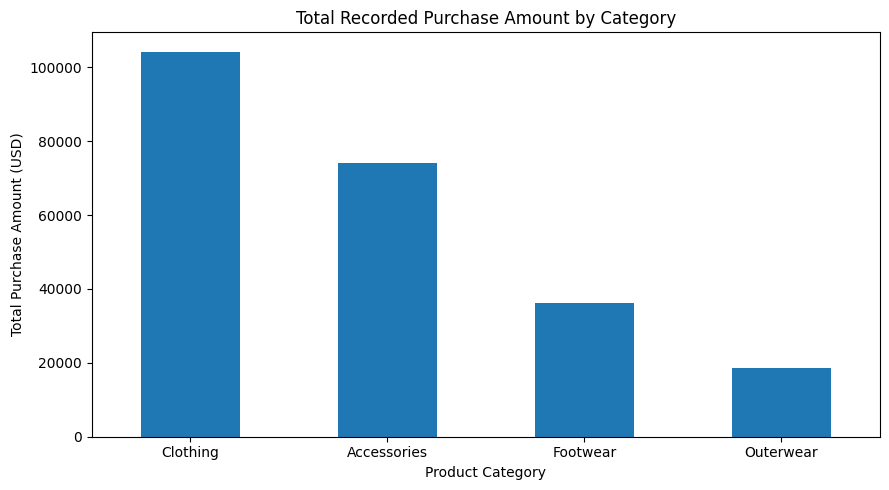

In [ ]:

import matplotlib.pyplot as plt

# Calculate total purchase amount by category
category_totals = (
    df_clean.groupby("category")["purchase_amount"]
    .sum()
    .sort_values(ascending=False)
)

# Create the bar chart
plt.figure(figsize=(9, 5))
category_totals.plot(kind="bar")

plt.title("Total Recorded Purchase Amount by Category")
plt.xlabel("Product Category")
plt.ylabel("Total Purchase Amount (USD)")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()


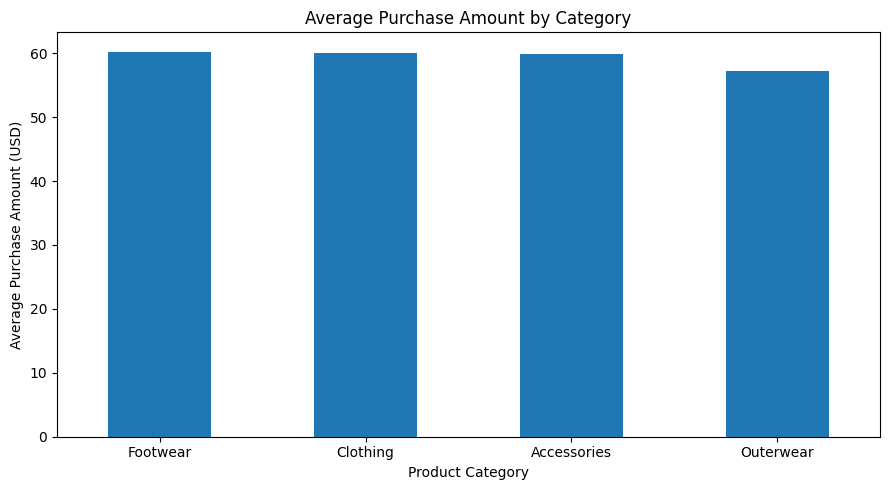

In [ ]:

# Average purchase amount by category
category_averages = (
    df_clean.groupby("category")["purchase_amount"]
    .mean()
    .sort_values(ascending=False)
)

plt.figure(figsize=(9, 5))
category_averages.plot(kind="bar")

plt.title("Average Purchase Amount by Category")
plt.xlabel("Product Category")
plt.ylabel("Average Purchase Amount (USD)")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()


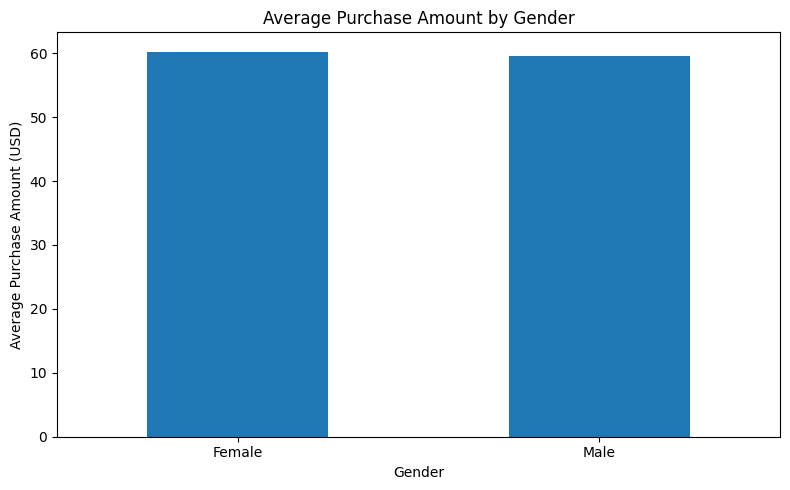

In [ ]:

# Average purchase amount by gender
gender_averages = (
    df_clean.groupby("gender")["purchase_amount"]
    .mean()
    .sort_values(ascending=False)
)

plt.figure(figsize=(8, 5))
gender_averages.plot(kind="bar")

plt.title("Average Purchase Amount by Gender")
plt.xlabel("Gender")
plt.ylabel("Average Purchase Amount (USD)")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()


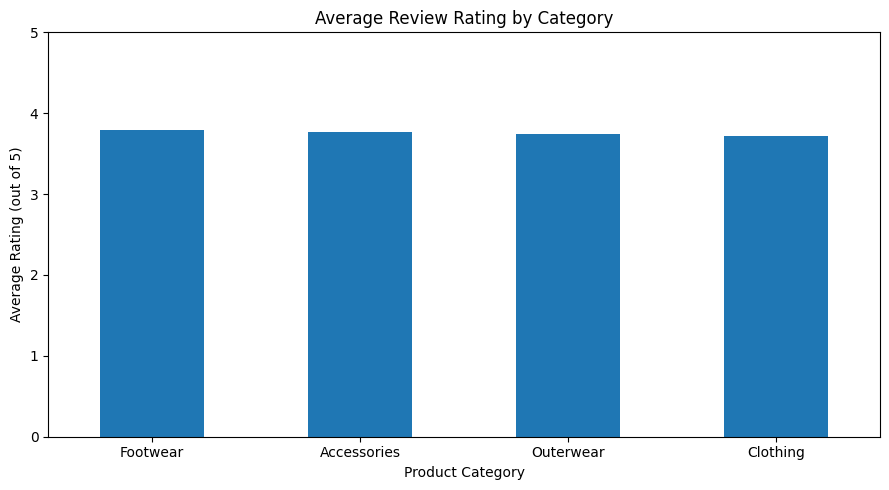

In [ ]:

# Average review rating by category
rating_by_category = (
    df_clean.groupby("category")["review_rating"]
    .mean()
    .sort_values(ascending=False)
)

plt.figure(figsize=(9, 5))
rating_by_category.plot(kind="bar")

plt.title("Average Review Rating by Category")
plt.xlabel("Product Category")
plt.ylabel("Average Rating (out of 5)")
plt.ylim(0, 5)
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()
yes

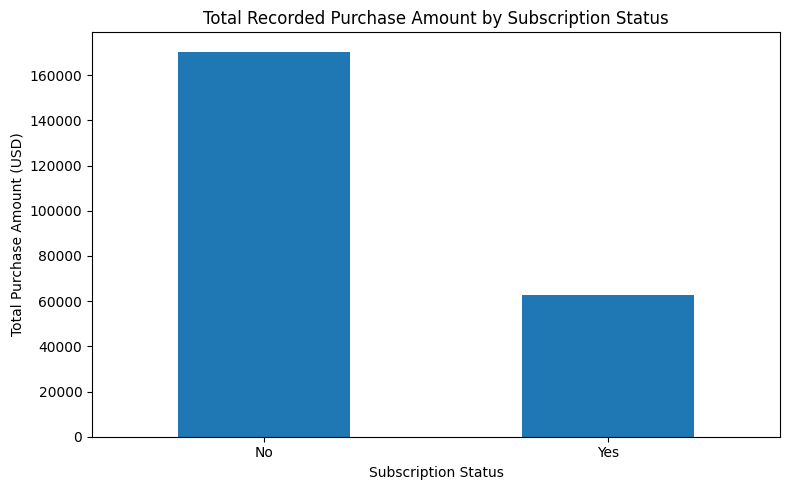

In [ ]:

# Total recorded purchase amount by subscription status
subscription_totals = (
    df_clean.groupby("subscription_status")["purchase_amount"]
    .sum()
    .sort_values(ascending=False)
)

plt.figure(figsize=(8, 5))
subscription_totals.plot(kind="bar")

plt.title("Total Recorded Purchase Amount by Subscription Status")
plt.xlabel("Subscription Status")
plt.ylabel("Total Purchase Amount (USD)")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()


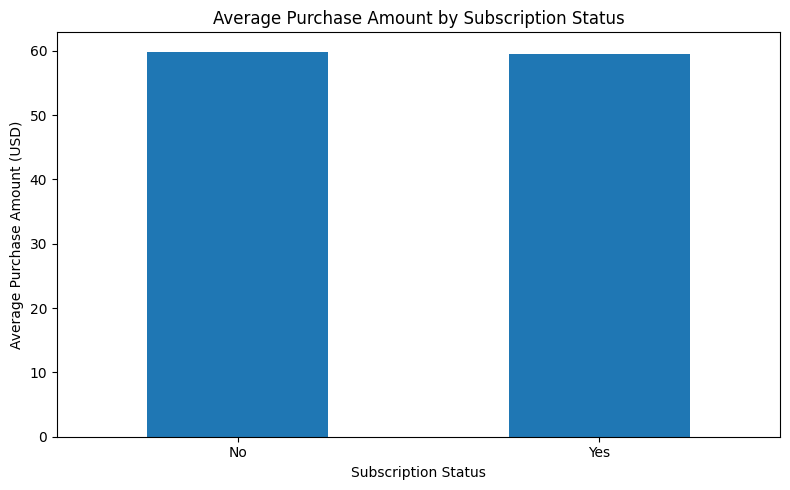

In [ ]:
subscription_averages = (
    df_clean.groupby("subscription_status")["purchase_amount"]
    .mean()
    .sort_values(ascending=False)
)

plt.figure(figsize=(8, 5))
subscription_averages.plot(kind="bar")

plt.title("Average Purchase Amount by Subscription Status")
plt.xlabel("Subscription Status")
plt.ylabel("Average Purchase Amount (USD)")
plt.xticks(rotation=0)

plt.tight_layout()
plt.show()

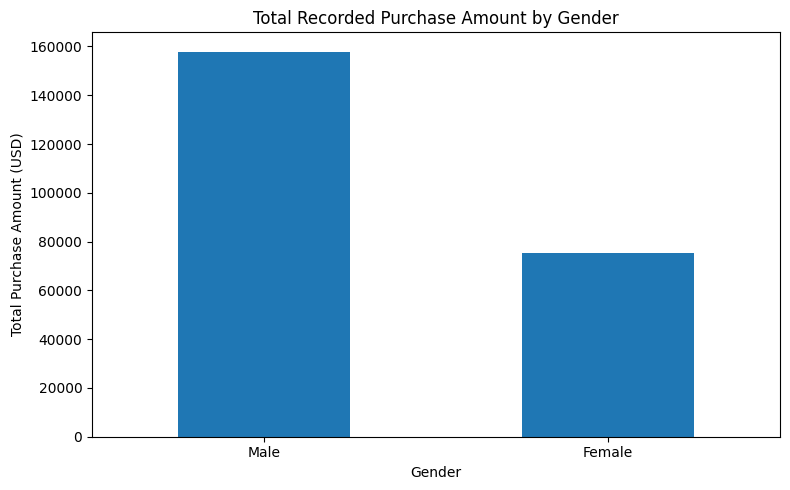

In [ ]:
gender_totals = (
    df_clean.groupby("gender")["purchase_amount"]
    .sum()
    .sort_values(ascending=False)
)

plt.figure(figsize=(8, 5))
gender_totals.plot(kind="bar")

plt.title("Total Recorded Purchase Amount by Gender")
plt.xlabel("Gender")
plt.ylabel("Total Purchase Amount (USD)")
plt.xticks(rotation=0)

plt.tight_layout()
plt.show()

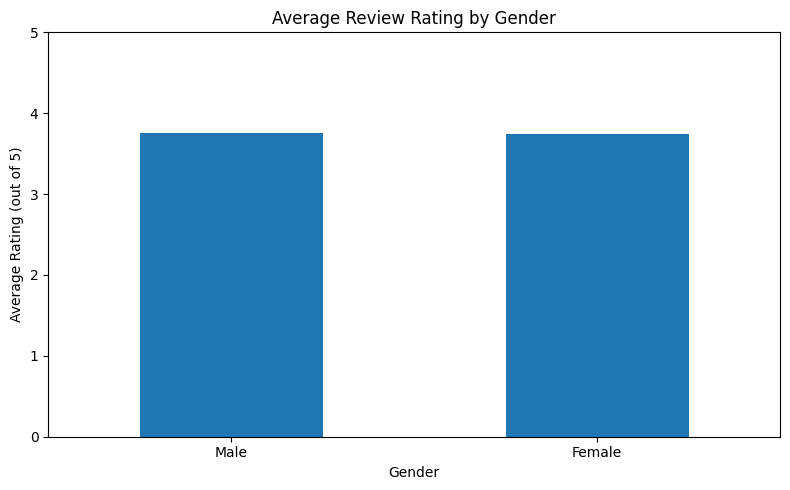

In [ ]:
rating_by_gender = (
    df_clean.groupby("gender")["review_rating"]
    .mean()
    .sort_values(ascending=False)
)

plt.figure(figsize=(8, 5))
rating_by_gender.plot(kind="bar")

plt.title("Average Review Rating by Gender")
plt.xlabel("Gender")
plt.ylabel("Average Rating (out of 5)")
plt.ylim(0, 5)
plt.xticks(rotation=0)

plt.tight_layout()
plt.show()

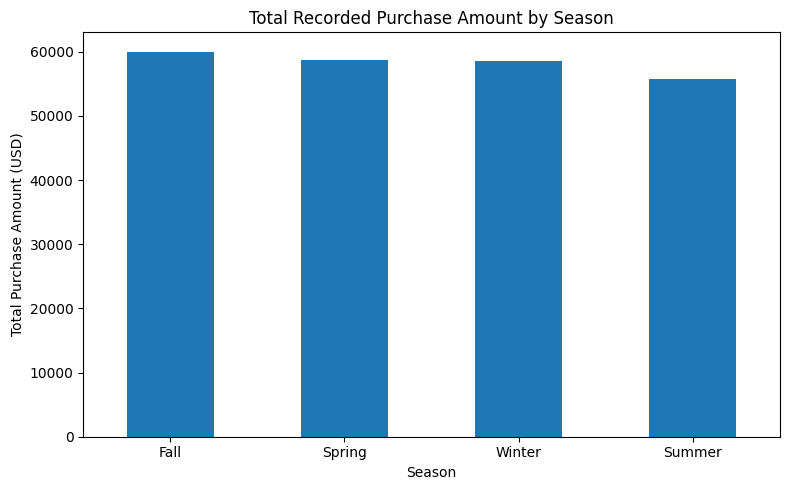

In [ ]:
season_totals = (
    df_clean.groupby("season")["purchase_amount"]
    .sum()
    .sort_values(ascending=False)
)

plt.figure(figsize=(8, 5))
season_totals.plot(kind="bar")

plt.title("Total Recorded Purchase Amount by Season")
plt.xlabel("Season")
plt.ylabel("Total Purchase Amount (USD)")
plt.xticks(rotation=0)

plt.tight_layout()
plt.show()

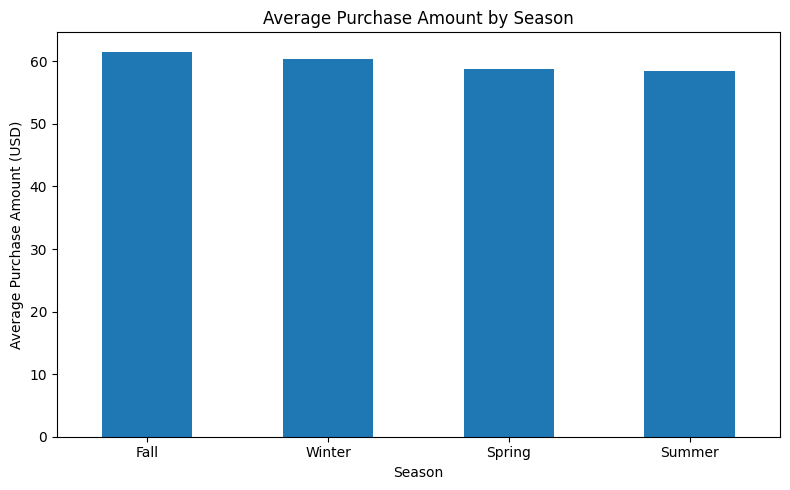

In [ ]:
season_averages = (
    df_clean.groupby("season")["purchase_amount"]
    .mean()
    .sort_values(ascending=False)
)

plt.figure(figsize=(8, 5))
season_averages.plot(kind="bar")

plt.title("Average Purchase Amount by Season")
plt.xlabel("Season")
plt.ylabel("Average Purchase Amount (USD)")
plt.xticks(rotation=0)

plt.tight_layout()
plt.show()

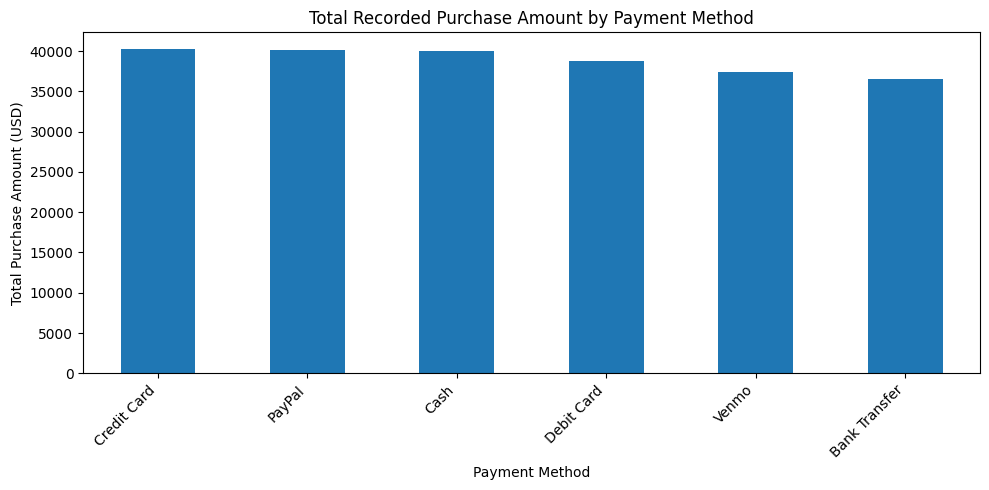

In [ ]:
payment_totals = (
    df_clean.groupby("payment_method")["purchase_amount"]
    .sum()
    .sort_values(ascending=False)
)

plt.figure(figsize=(10, 5))
payment_totals.plot(kind="bar")

plt.title("Total Recorded Purchase Amount by Payment Method")
plt.xlabel("Payment Method")
plt.ylabel("Total Purchase Amount (USD)")
plt.xticks(rotation=45, ha="right")

plt.tight_layout()
plt.show()

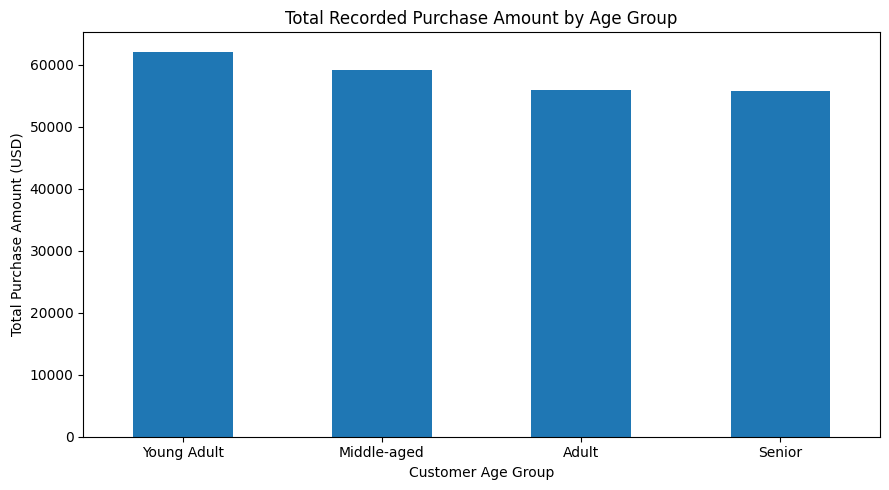

In [ ]:
age_group_totals = (
    df_clean.groupby("age_group", observed=True)["purchase_amount"]
    .sum()
    .sort_values(ascending=False)
)

plt.figure(figsize=(9, 5))
age_group_totals.plot(kind="bar")

plt.title("Total Recorded Purchase Amount by Age Group")
plt.xlabel("Customer Age Group")
plt.ylabel("Total Purchase Amount (USD)")
plt.xticks(rotation=0)

plt.tight_layout()
plt.show()

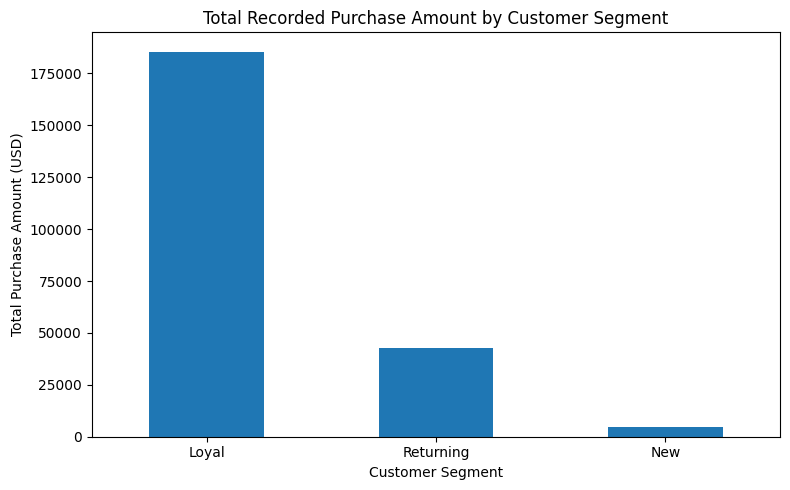

In [ ]:
segment_totals = (
    df_clean.groupby("customer_segment", observed=True)["purchase_amount"]
    .sum()
    .sort_values(ascending=False)
)

plt.figure(figsize=(8, 5))
segment_totals.plot(kind="bar")

plt.title("Total Recorded Purchase Amount by Customer Segment")
plt.xlabel("Customer Segment")
plt.ylabel("Total Purchase Amount (USD)")
plt.xticks(rotation=0)

plt.tight_layout()
plt.show()

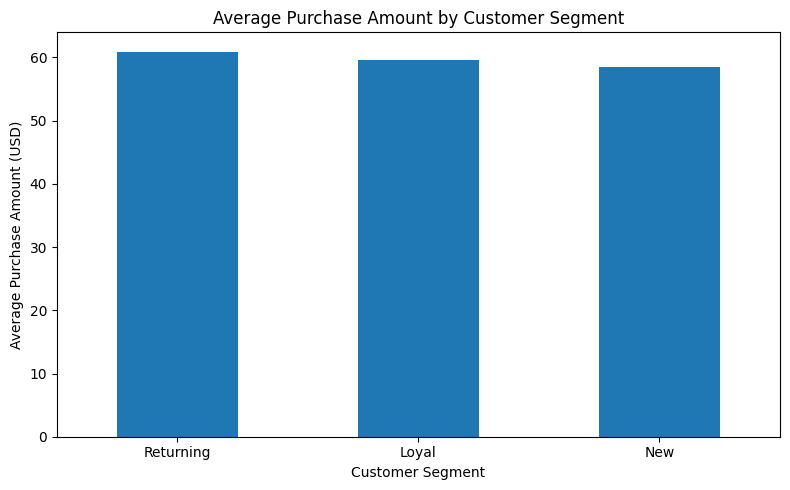

In [ ]:
segment_averages = (
    df_clean.groupby("customer_segment", observed=True)["purchase_amount"]
    .mean()
    .sort_values(ascending=False)
)

plt.figure(figsize=(8, 5))
segment_averages.plot(kind="bar")

plt.title("Average Purchase Amount by Customer Segment")
plt.xlabel("Customer Segment")
plt.ylabel("Average Purchase Amount (USD)")
plt.xticks(rotation=0)

plt.tight_layout()
plt.show()

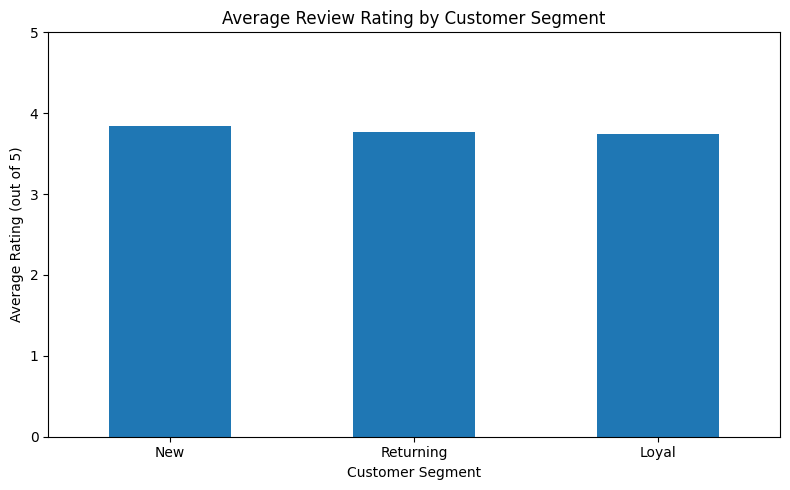

In [ ]:
segment_ratings = (
    df_clean.groupby("customer_segment", observed=True)["review_rating"]
    .mean()
    .sort_values(ascending=False)
)

plt.figure(figsize=(8, 5))
segment_ratings.plot(kind="bar")

plt.title("Average Review Rating by Customer Segment")
plt.xlabel("Customer Segment")
plt.ylabel("Average Rating (out of 5)")
plt.ylim(0, 5)
plt.xticks(rotation=0)

plt.tight_layout()
plt.show()

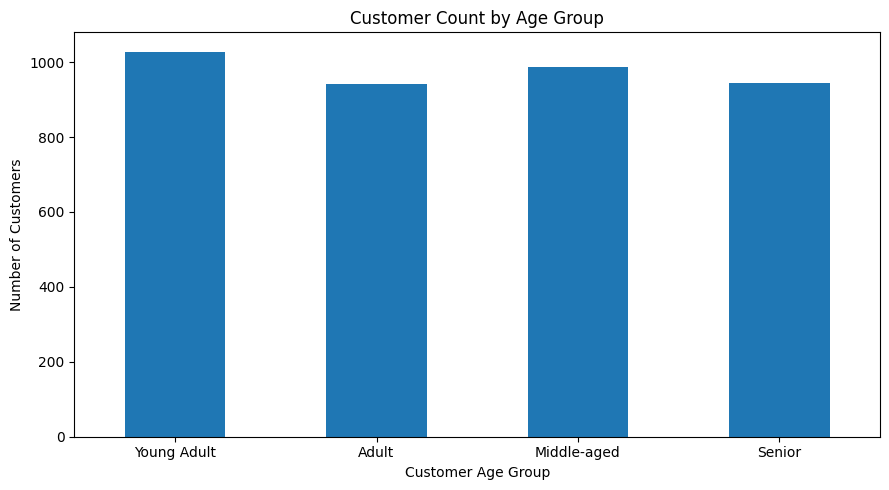

In [ ]:
age_group_counts = (
    df_clean["age_group"]
    .value_counts()
    .reindex(["Young Adult", "Adult", "Middle-aged", "Senior"])
)

plt.figure(figsize=(9, 5))
age_group_counts.plot(kind="bar")

plt.title("Customer Count by Age Group")
plt.xlabel("Customer Age Group")
plt.ylabel("Number of Customers")
plt.xticks(rotation=0)

plt.tight_layout()
plt.show()

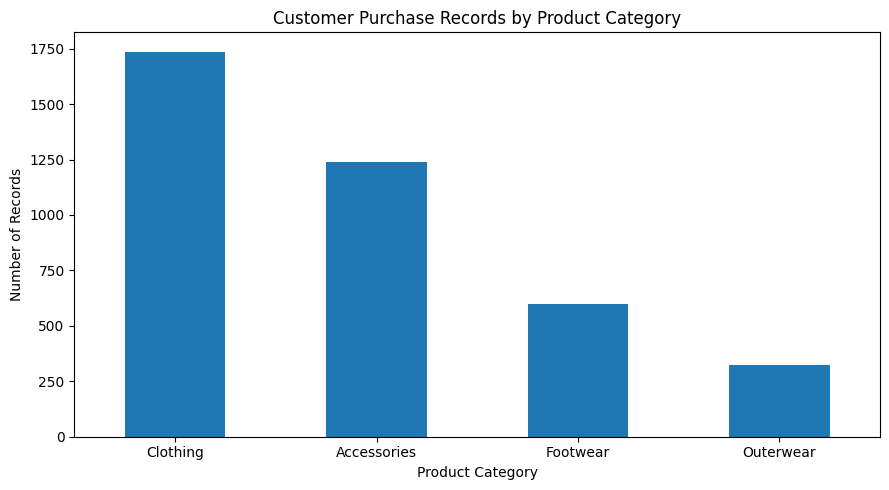

In [ ]:
category_counts = (
    df_clean["category"]
    .value_counts()
    .sort_values(ascending=False)
)

plt.figure(figsize=(9, 5))
category_counts.plot(kind="bar")

plt.title("Customer Purchase Records by Product Category")
plt.xlabel("Product Category")
plt.ylabel("Number of Records")
plt.xticks(rotation=0)

plt.tight_layout()
plt.show()

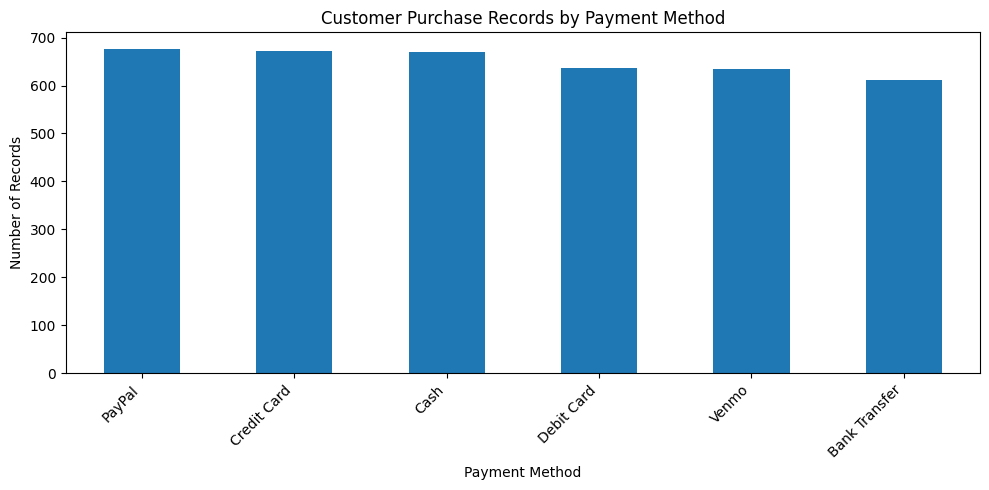

In [ ]:
payment_counts = (
    df_clean["payment_method"]
    .value_counts()
    .sort_values(ascending=False)
)

plt.figure(figsize=(10, 5))
payment_counts.plot(kind="bar")

plt.title("Customer Purchase Records by Payment Method")
plt.xlabel("Payment Method")
plt.ylabel("Number of Records")
plt.xticks(rotation=45, ha="right")

plt.tight_layout()
plt.show()

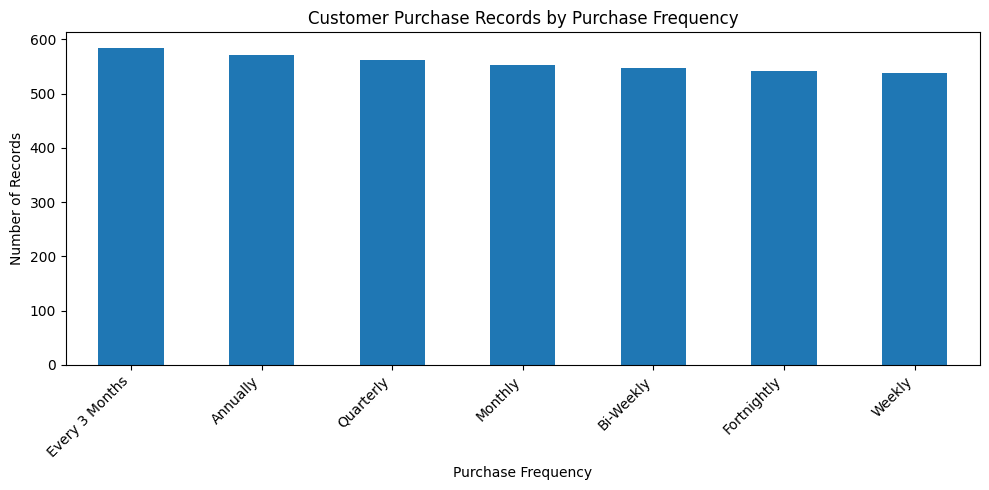

In [ ]:
frequency_counts = (
    df_clean["frequency_of_purchases"]
    .value_counts()
    .sort_values(ascending=False)
)

plt.figure(figsize=(10, 5))
frequency_counts.plot(kind="bar")

plt.title("Customer Purchase Records by Purchase Frequency")
plt.xlabel("Purchase Frequency")
plt.ylabel("Number of Records")
plt.xticks(rotation=45, ha="right")

plt.tight_layout()
plt.show()

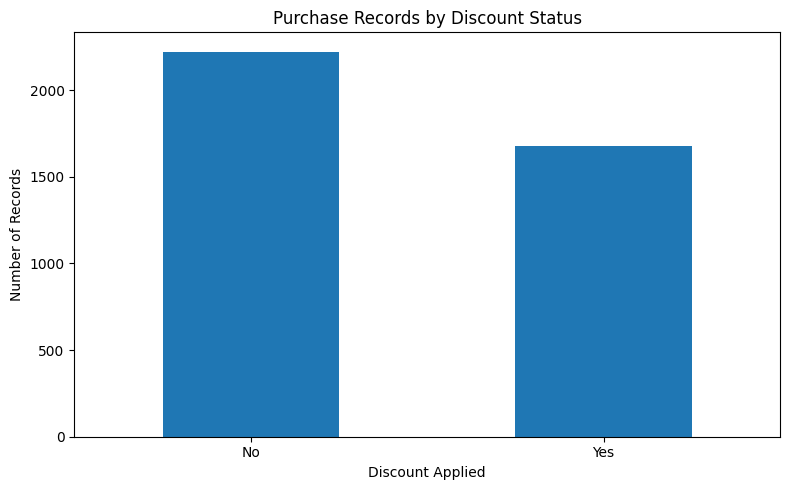

In [ ]:
discount_counts = df_clean["discount_applied"].value_counts()

plt.figure(figsize=(8, 5))
discount_counts.plot(kind="bar")

plt.title("Purchase Records by Discount Status")
plt.xlabel("Discount Applied")
plt.ylabel("Number of Records")
plt.xticks(rotation=0)

plt.tight_layout()
plt.show()


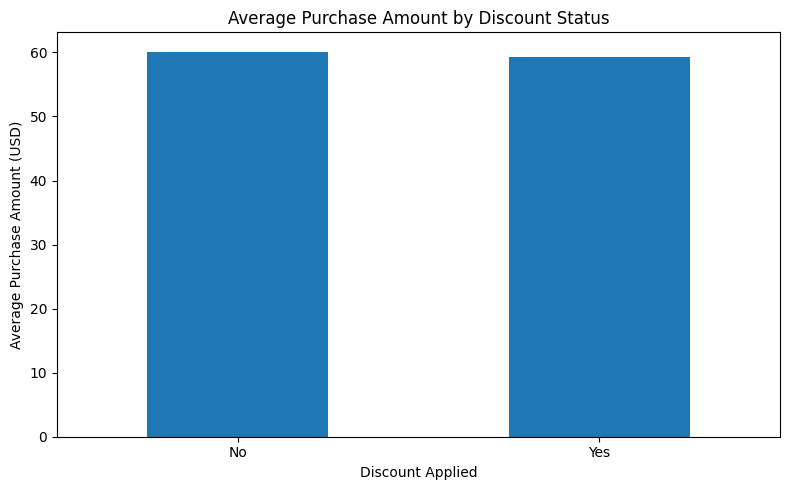

In [ ]:
discount_averages = (
    df_clean.groupby("discount_applied")["purchase_amount"]
    .mean()
    .sort_values(ascending=False)
)

plt.figure(figsize=(8, 5))
discount_averages.plot(kind="bar")

plt.title("Average Purchase Amount by Discount Status")
plt.xlabel("Discount Applied")
plt.ylabel("Average Purchase Amount (USD)")
plt.xticks(rotation=0)

plt.tight_layout()
plt.show()

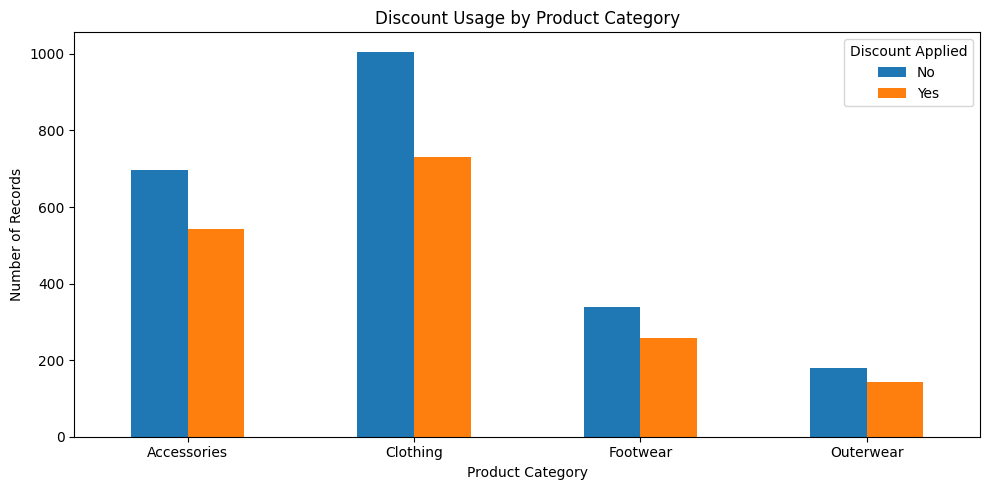

In [ ]:
discount_category_counts = (
    df_clean.groupby(["category", "discount_applied"])
    .size()
    .unstack(fill_value=0)
)

discount_category_counts.plot(
    kind="bar",
    figsize=(10, 5)
)

plt.title("Discount Usage by Product Category")
plt.xlabel("Product Category")
plt.ylabel("Number of Records")
plt.xticks(rotation=0)
plt.legend(title="Discount Applied")

plt.tight_layout()
plt.show()

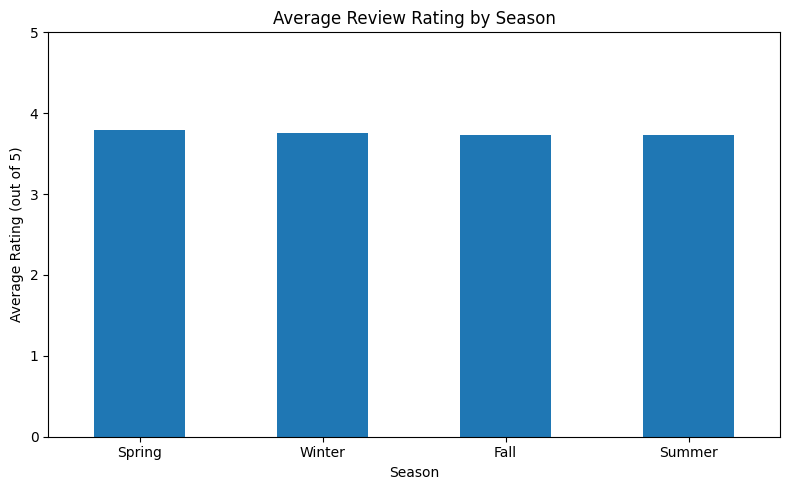

In [ ]:
season_ratings = (
    df_clean.groupby("season")["review_rating"]
    .mean()
    .sort_values(ascending=False)
)

plt.figure(figsize=(8, 5))
season_ratings.plot(kind="bar")

plt.title("Average Review Rating by Season")
plt.xlabel("Season")
plt.ylabel("Average Rating (out of 5)")
plt.ylim(0, 5)
plt.xticks(rotation=0)

plt.tight_layout()
plt.show()

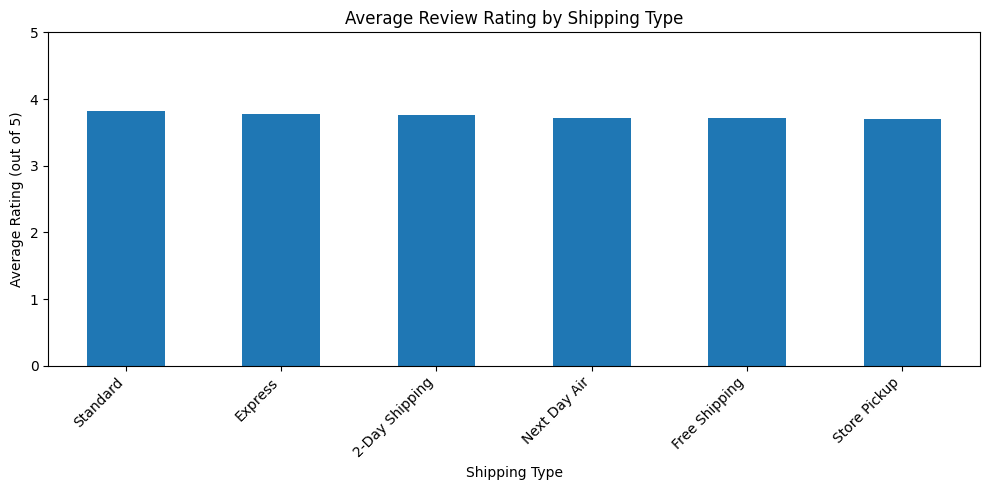

In [ ]:
shipping_ratings = (
    df_clean.groupby("shipping_type")["review_rating"]
    .mean()
    .sort_values(ascending=False)
)

plt.figure(figsize=(10, 5))
shipping_ratings.plot(kind="bar")

plt.title("Average Review Rating by Shipping Type")
plt.xlabel("Shipping Type")
plt.ylabel("Average Rating (out of 5)")
plt.ylim(0, 5)
plt.xticks(rotation=45, ha="right")

plt.tight_layout()
plt.show()

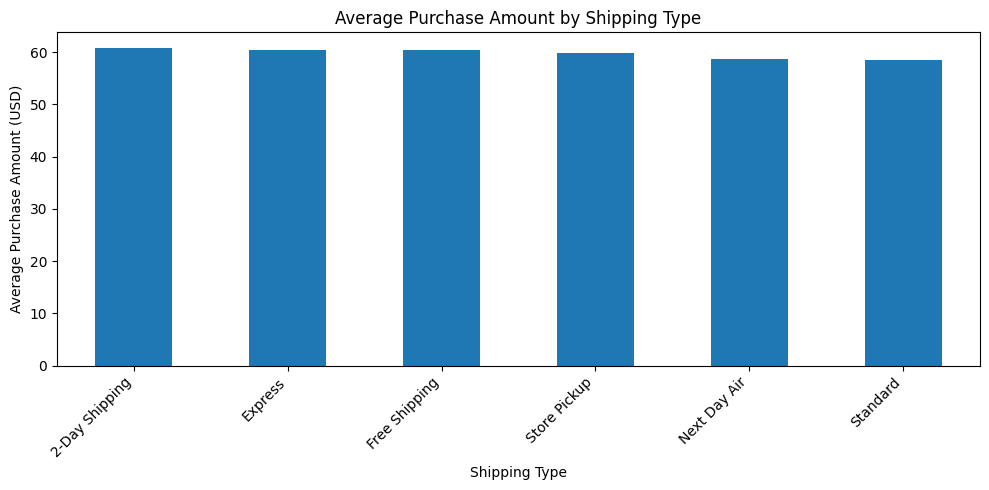

In [ ]:
shipping_averages = (
    df_clean.groupby("shipping_type")["purchase_amount"]
    .mean()
    .sort_values(ascending=False)
)

plt.figure(figsize=(10, 5))
shipping_averages.plot(kind="bar")

plt.title("Average Purchase Amount by Shipping Type")
plt.xlabel("Shipping Type")
plt.ylabel("Average Purchase Amount (USD)")
plt.xticks(rotation=45, ha="right")

plt.tight_layout()
plt.show()

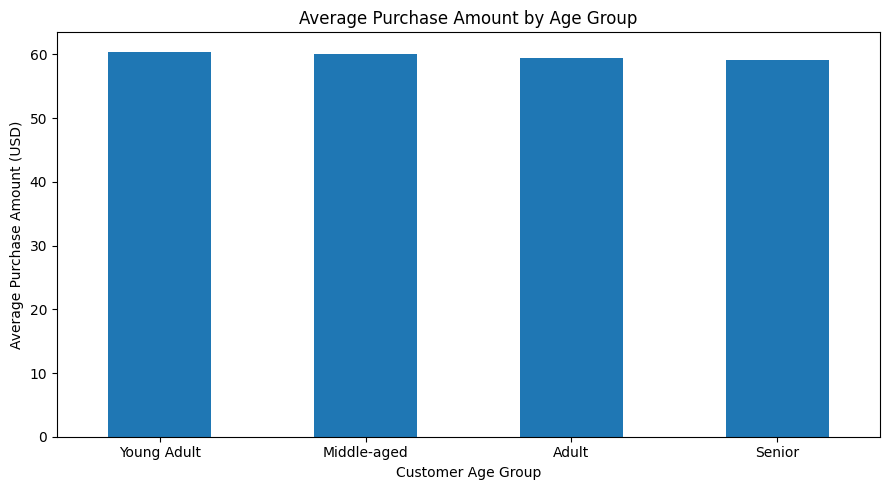

In [ ]:
age_group_averages = (
    df_clean.groupby("age_group", observed=True)["purchase_amount"]
    .mean()
    .sort_values(ascending=False)
)

plt.figure(figsize=(9, 5))
age_group_averages.plot(kind="bar")

plt.title("Average Purchase Amount by Age Group")
plt.xlabel("Customer Age Group")
plt.ylabel("Average Purchase Amount (USD)")
plt.xticks(rotation=0)

plt.tight_layout()
plt.show()

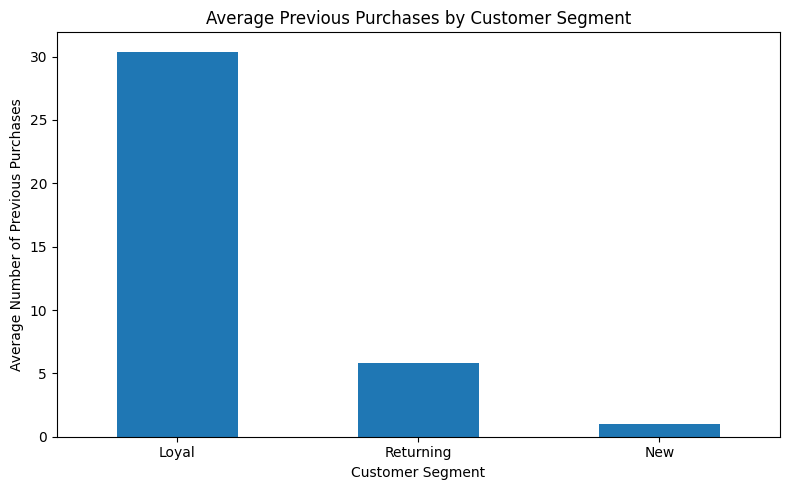

In [ ]:
segment_purchase_history = (
    df_clean.groupby("customer_segment", observed=True)["previous_purchases"]
    .mean()
    .sort_values(ascending=False)
)

plt.figure(figsize=(8, 5))
segment_purchase_history.plot(kind="bar")

plt.title("Average Previous Purchases by Customer Segment")
plt.xlabel("Customer Segment")
plt.ylabel("Average Number of Previous Purchases")
plt.xticks(rotation=0)

plt.tight_layout()
plt.show()

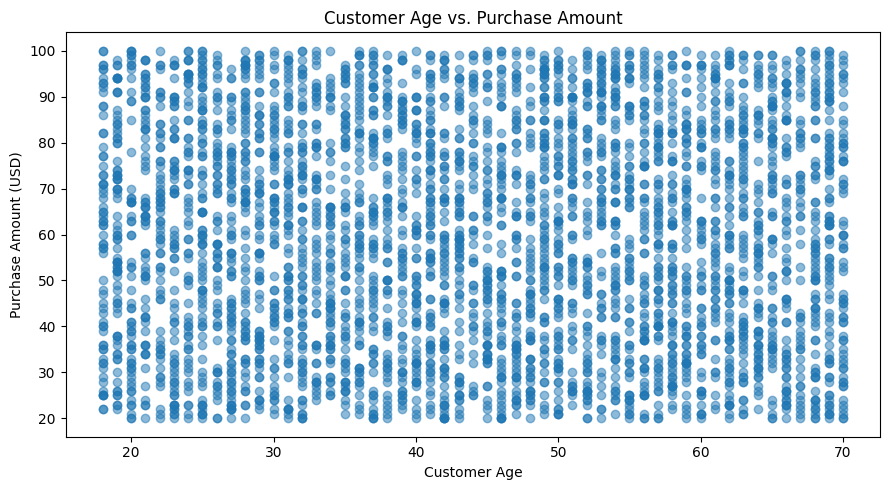

In [ ]:
plt.figure(figsize=(9, 5))

plt.scatter(
    df_clean["age"],
    df_clean["purchase_amount"],
    alpha=0.5
)

plt.title("Customer Age vs. Purchase Amount")
plt.xlabel("Customer Age")
plt.ylabel("Purchase Amount (USD)")

plt.tight_layout()
plt.show()

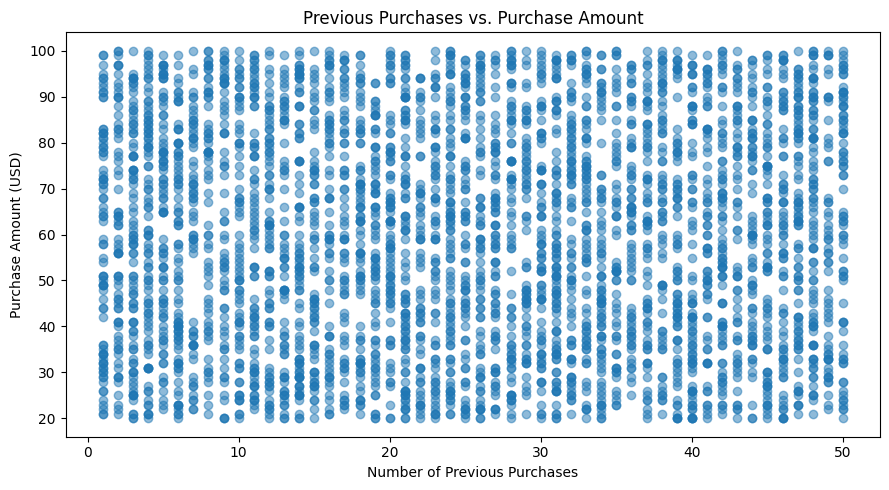

In [ ]:
plt.figure(figsize=(9, 5))

plt.scatter(
    df_clean["previous_purchases"],
    df_clean["purchase_amount"],
    alpha=0.5
)

plt.title("Previous Purchases vs. Purchase Amount")
plt.xlabel("Number of Previous Purchases")
plt.ylabel("Purchase Amount (USD)")

plt.tight_layout()
plt.show()

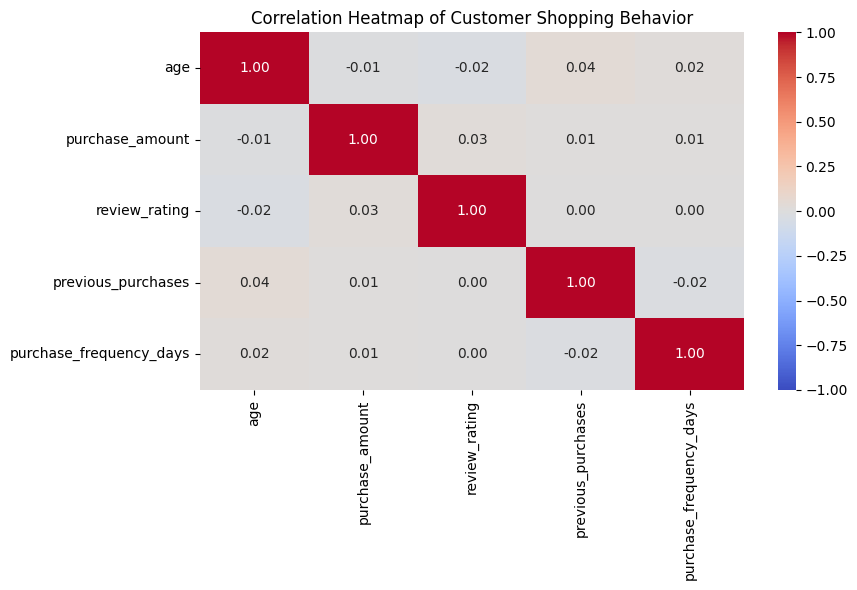

In [ ]:
import seaborn as sns
import matplotlib.pyplot as plt

numerical_columns = [
    "age",
    "purchase_amount",
    "review_rating",
    "previous_purchases",
    "purchase_frequency_days"
]

correlation_matrix = df_clean[numerical_columns].corr()

plt.figure(figsize=(9, 6))

sns.heatmap(
    correlation_matrix,
    annot=True,
    cmap="coolwarm",
    fmt=".2f",
    vmin=-1,
    vmax=1
)

plt.title("Correlation Heatmap of Customer Shopping Behavior")
plt.tight_layout()
plt.show()

In [ ]:
top_products = (
    df_clean.groupby("item_purchased")["purchase_amount"]
    .agg(["sum", "count", "mean"])
    .sort_values("sum", ascending=False)
    .head(10)
)

top_products = top_products.rename(columns={
    "sum": "total_purchase_amount",
    "count": "number_of_records",
    "mean": "average_purchase_amount"
})

display(top_products.round(2))

NameError: name 'df_clean' is not defined

In [ ]:
import pandas as pd

df_clean = pd.read_csv("customer_shopping_behavior_cleaned.csv")

print("Dataset loaded successfully!")
print("Shape:", df_clean.shape)
display(df_clean.head())

FileNotFoundError: [Errno 2] No such file or directory: 'customer_shopping_behavior_cleaned.csv'

In [ ]:
from google.colab import files
uploaded = files.upload()

Saving customer_shopping_behavior_cleaned.csv to customer_shopping_behavior_cleaned.csv


In [ ]:
import pandas as pd

df_clean = pd.read_csv("customer_shopping_behavior_cleaned.csv")

print("Dataset loaded successfully!")
print("Shape:", df_clean.shape)
print("Columns:", df_clean.columns.tolist())

display(df_clean.head())

Dataset loaded successfully!
Shape: (3900, 20)
Columns: ['customer_id', 'age', 'gender', 'item_purchased', 'category', 'purchase_amount', 'location', 'size', 'color', 'season', 'review_rating', 'subscription_status', 'shipping_type', 'discount_applied', 'promo_code_used', 'previous_purchases', 'payment_method', 'frequency_of_purchases', 'age_group', 'purchase_frequency_days']


,customer_id,age,gender,item_purchased,category,purchase_amount,location,size,color,season,review_rating,subscription_status,shipping_type,discount_applied,promo_code_used,previous_purchases,payment_method,frequency_of_purchases,age_group,purchase_frequency_days
0,1,55,Male,Blouse,Clothing,53,Kentucky,L,Gray,Winter,3.1,Yes,Express,Yes,Yes,14,Venmo,Fortnightly,Middle-aged,14
1,2,19,Male,Sweater,Clothing,64,Maine,L,Maroon,Winter,3.1,Yes,Express,Yes,Yes,2,Cash,Fortnightly,Young Adult,14
2,3,50,Male,Jeans,Clothing,73,Massachusetts,S,Maroon,Spring,3.1,Yes,Free Shipping,Yes,Yes,23,Credit Card,Weekly,Middle-aged,7
3,4,21,Male,Sandals,Footwear,90,Rhode Island,M,Maroon,Spring,3.5,Yes,Next Day Air,Yes,Yes,49,PayPal,Weekly,Young Adult,7
4,5,45,Male,Blouse,Clothing,49,Oregon,M,Turquoise,Spring,2.7,Yes,Free Shipping,Yes,Yes,31,PayPal,Annually,Middle-aged,365


In [ ]:
top_products = (
    df_clean.groupby("item_purchased")["purchase_amount"]
    .agg(["sum", "count", "mean"])
    .sort_values("sum", ascending=False)
    .head(10)
)

top_products = top_products.rename(columns={
    "sum": "total_purchase_amount",
    "count": "number_of_records",
    "mean": "average_purchase_amount"
})

display(top_products.round(2))

,total_purchase_amount,number_of_records,average_purchase_amount
item_purchased,,,
Blouse,10410,171,60.88
Shirt,10332,169,61.14
Dress,10320,166,62.17
Pants,10090,171,59.01
Jewelry,10010,171,58.54
Sunglasses,9649,161,59.93
Belt,9635,161,59.84
Scarf,9561,157,60.90
Sweater,9462,164,57.70


In [ ]:
plt.figure(figsize=(12, 6))

top_products["total_purchase_amount"].plot(kind="bar")

plt.title("Top 10 Products by Total Recorded Purchase Amount")
plt.xlabel("Product")
plt.ylabel("Total Purchase Amount (USD)")
plt.xticks(rotation=45, ha="right")

plt.tight_layout()
plt.show()

NameError: name 'plt' is not defined

In [ ]:
import matplotlib.pyplot as plt

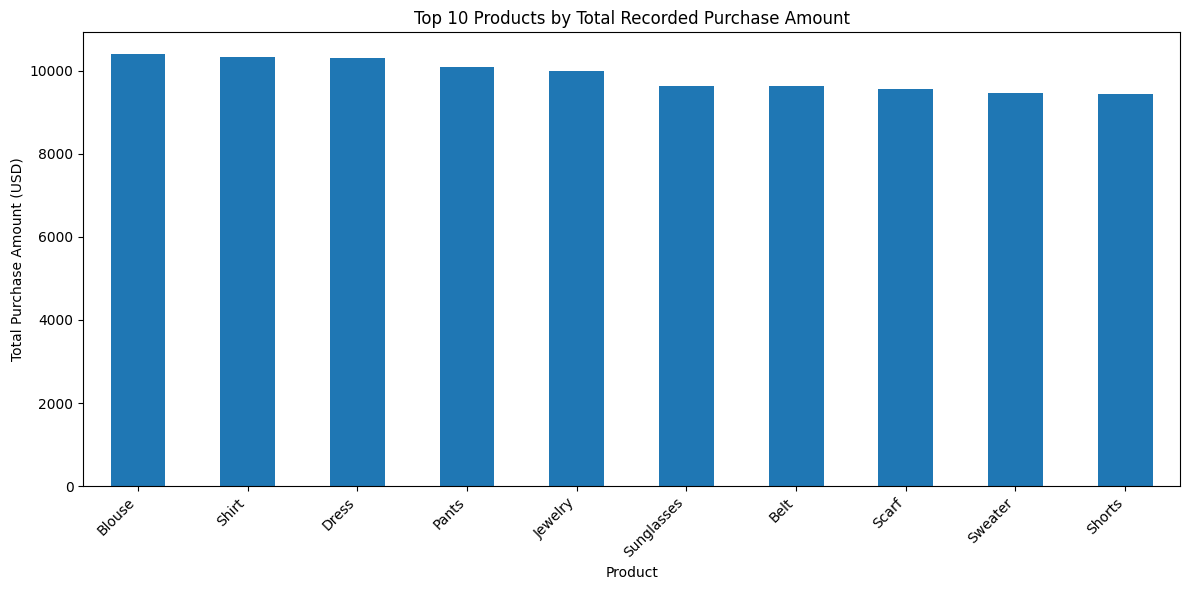

In [ ]:
plt.figure(figsize=(12, 6))

top_products["total_purchase_amount"].plot(kind="bar")

plt.title("Top 10 Products by Total Recorded Purchase Amount")
plt.xlabel("Product")
plt.ylabel("Total Purchase Amount (USD)")
plt.xticks(rotation=45, ha="right")

plt.tight_layout()
plt.show()

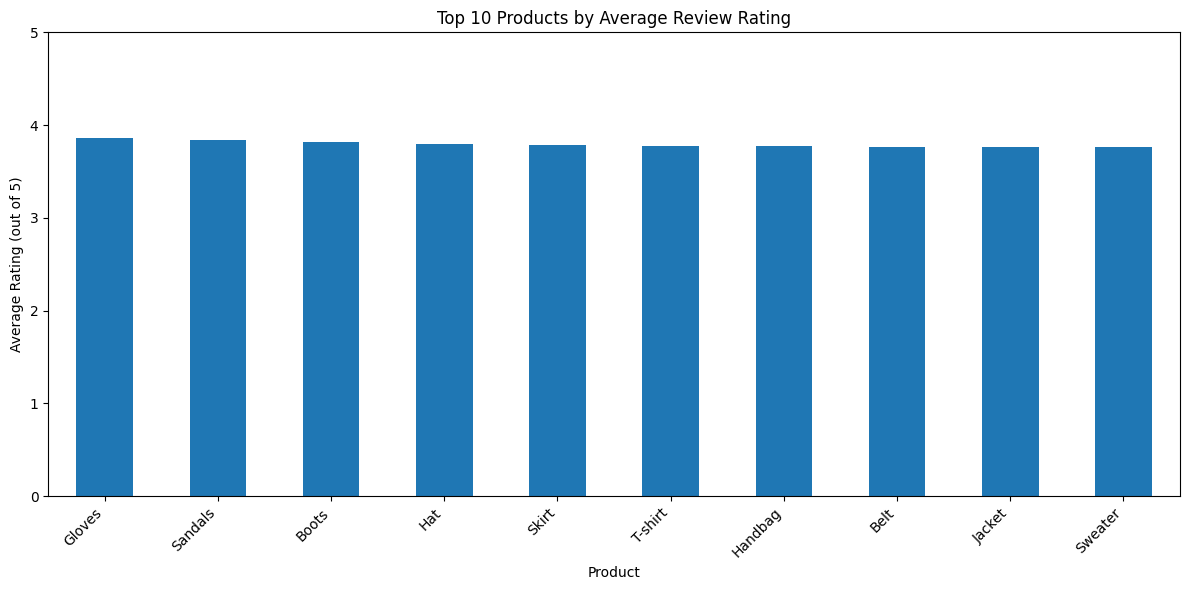

In [ ]:
top_rated_products = (
    df_clean.groupby("item_purchased")
    .agg(
        average_rating=("review_rating", "mean"),
        number_of_records=("review_rating", "count")
    )
    .sort_values(
        ["average_rating", "number_of_records"],
        ascending=[False, False]
    )
    .head(10)
)

plt.figure(figsize=(12, 6))

top_rated_products["average_rating"].plot(kind="bar")

plt.title("Top 10 Products by Average Review Rating")
plt.xlabel("Product")
plt.ylabel("Average Rating (out of 5)")
plt.ylim(0, 5)
plt.xticks(rotation=45, ha="right")

plt.tight_layout()
plt.show()

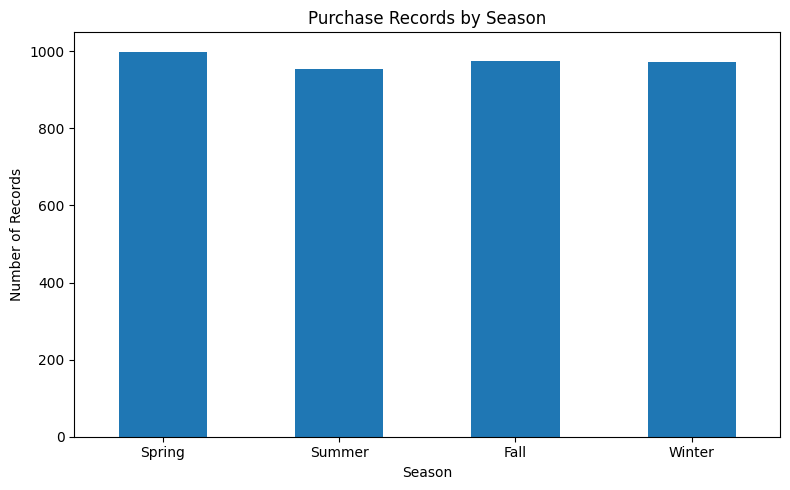

In [ ]:
season_counts = (
    df_clean["season"]
    .value_counts()
    .reindex(["Spring", "Summer", "Fall", "Winter"])
)

plt.figure(figsize=(8, 5))
season_counts.plot(kind="bar")

plt.title("Purchase Records by Season")
plt.xlabel("Season")
plt.ylabel("Number of Records")
plt.xticks(rotation=0)

plt.tight_layout()
plt.show()

In [ ]:
segment_counts = (
    df_clean["customer_segment"]
    .value_counts()
    .reindex(["New", "Returning", "Loyal"])
)

plt.figure(figsize=(8, 5))
segment_counts.plot(kind="bar")

plt.title("Purchase Records by Customer Segment")
plt.xlabel("Customer Segment")
plt.ylabel("Number of Records")
plt.xticks(rotation=0)

plt.tight_layout()
plt.show()

KeyError: 'customer_segment'

In [ ]:
import pandas as pd

df_clean["customer_segment"] = pd.cut(
    df_clean["previous_purchases"],
    bins=[0, 1, 10, float("inf")],
    labels=["New", "Returning", "Loyal"],
    include_lowest=True
)

print(df_clean["customer_segment"].value_counts())

customer_segment
Loyal        3116
Returning     701
New            83
Name: count, dtype: int64


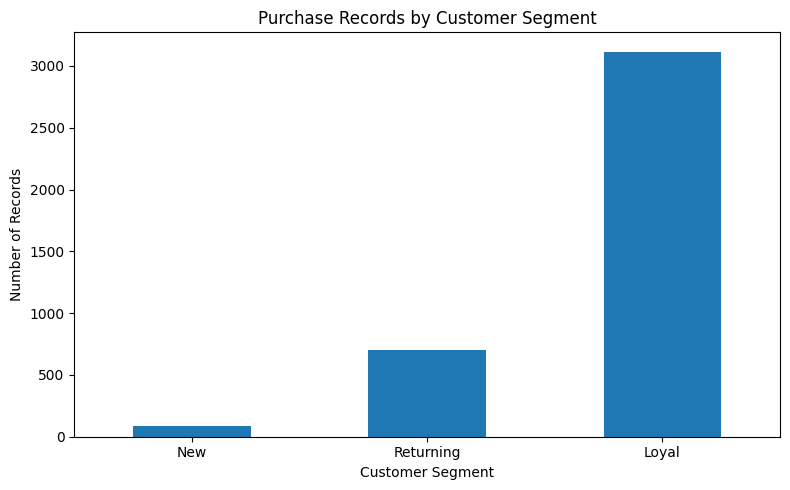

In [ ]:
segment_counts = (
    df_clean["customer_segment"]
    .value_counts()
    .reindex(["New", "Returning", "Loyal"])
)

plt.figure(figsize=(8, 5))
segment_counts.plot(kind="bar")

plt.title("Purchase Records by Customer Segment")
plt.xlabel("Customer Segment")
plt.ylabel("Number of Records")
plt.xticks(rotation=0)

plt.tight_layout()
plt.show()

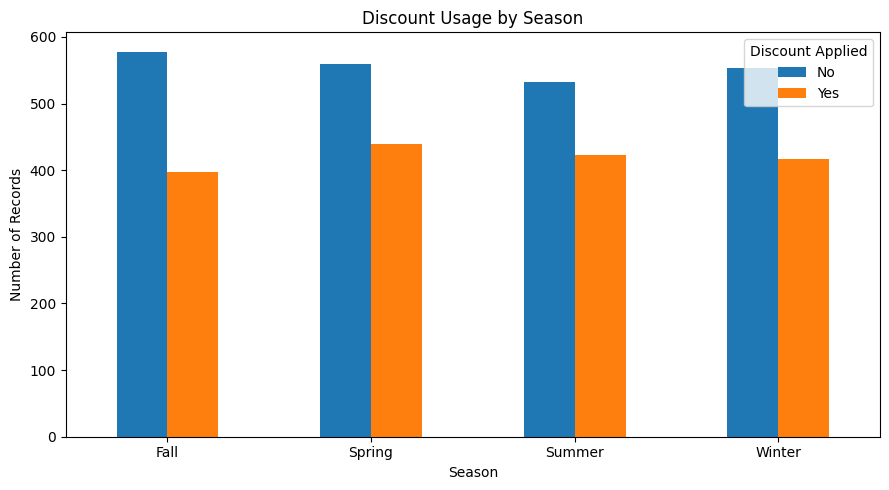

In [ ]:
discount_season_counts = (
    df_clean.groupby(["season", "discount_applied"])
    .size()
    .unstack(fill_value=0)
)

discount_season_counts.plot(
    kind="bar",
    figsize=(9, 5)
)

plt.title("Discount Usage by Season")
plt.xlabel("Season")
plt.ylabel("Number of Records")
plt.xticks(rotation=0)
plt.legend(title="Discount Applied")

plt.tight_layout()
plt.show()

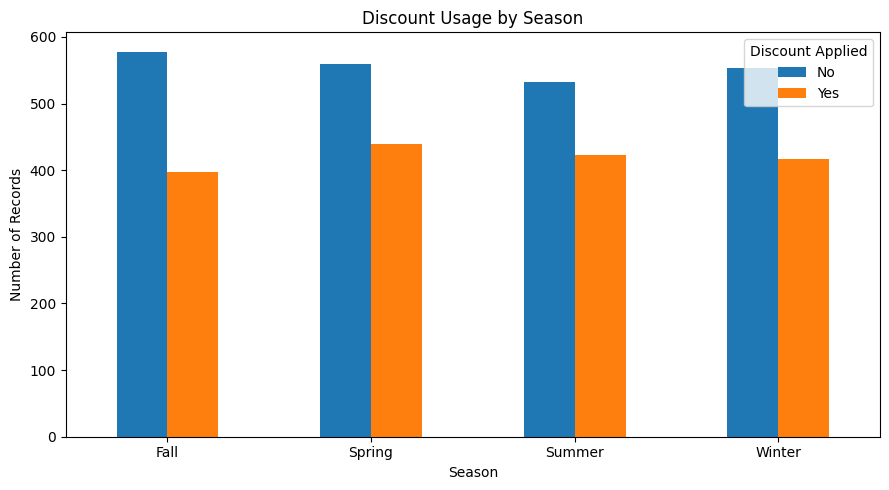

In [ ]:
discount_season_counts = (
    df_clean.groupby(["season", "discount_applied"])
    .size()
    .unstack(fill_value=0)
)

discount_season_counts.plot(
    kind="bar",
    figsize=(9, 5)
)

plt.title("Discount Usage by Season")
plt.xlabel("Season")
plt.ylabel("Number of Records")
plt.xticks(rotation=0)
plt.legend(title="Discount Applied")

plt.tight_layout()
plt.show()

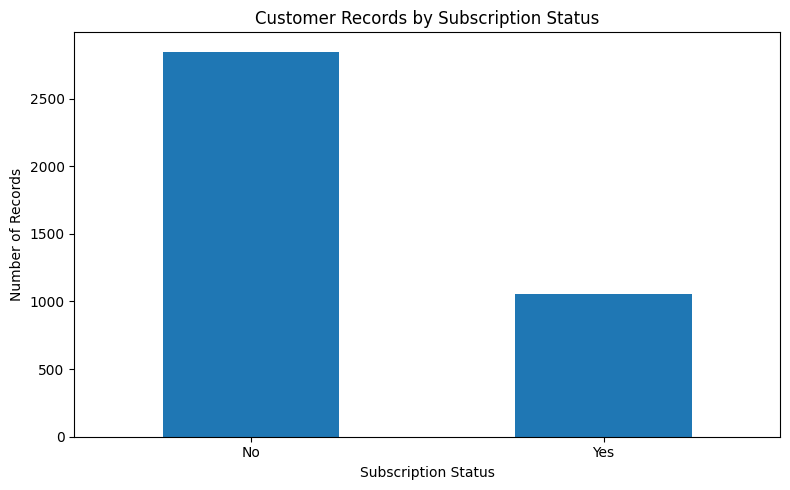

In [ ]:
subscription_counts = df_clean["subscription_status"].value_counts()

plt.figure(figsize=(8, 5))
subscription_counts.plot(kind="bar")

plt.title("Customer Records by Subscription Status")
plt.xlabel("Subscription Status")
plt.ylabel("Number of Records")
plt.xticks(rotation=0)

plt.tight_layout()
plt.show()

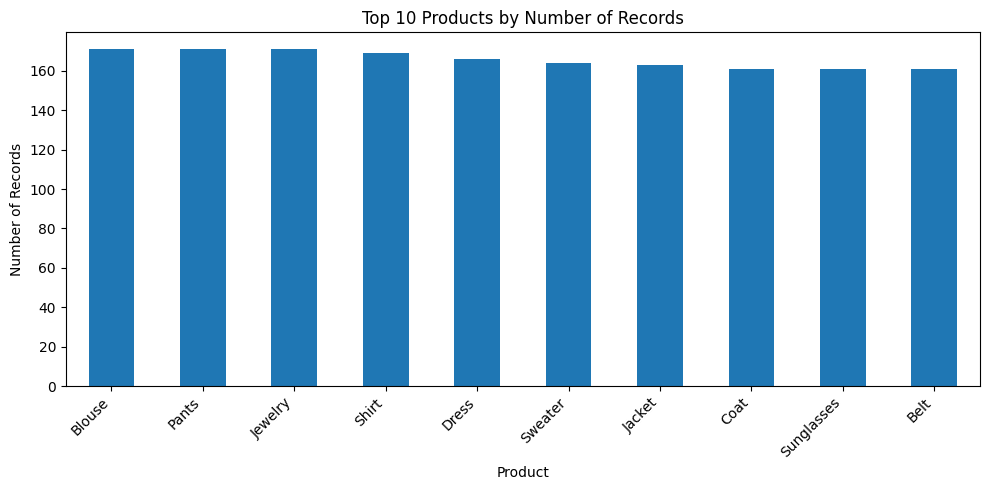

In [ ]:
product_counts = (
    df_clean["item_purchased"]
    .value_counts()
    .head(10)
)

plt.figure(figsize=(10, 5))
product_counts.plot(kind="bar")

plt.title("Top 10 Products by Number of Records")
plt.xlabel("Product")
plt.ylabel("Number of Records")
plt.xticks(rotation=45, ha="right")

plt.tight_layout()
plt.show()

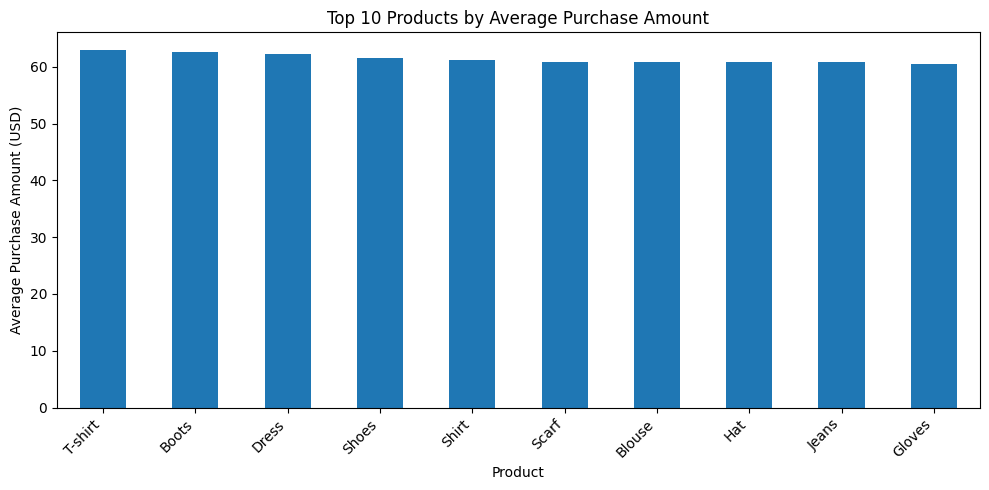

In [ ]:
product_averages = (
    df_clean.groupby("item_purchased")["purchase_amount"]
    .mean()
    .sort_values(ascending=False)
    .head(10)
)

plt.figure(figsize=(10, 5))
product_averages.plot(kind="bar")

plt.title("Top 10 Products by Average Purchase Amount")
plt.xlabel("Product")
plt.ylabel("Average Purchase Amount (USD)")
plt.xticks(rotation=45, ha="right")

plt.tight_layout()
plt.show()

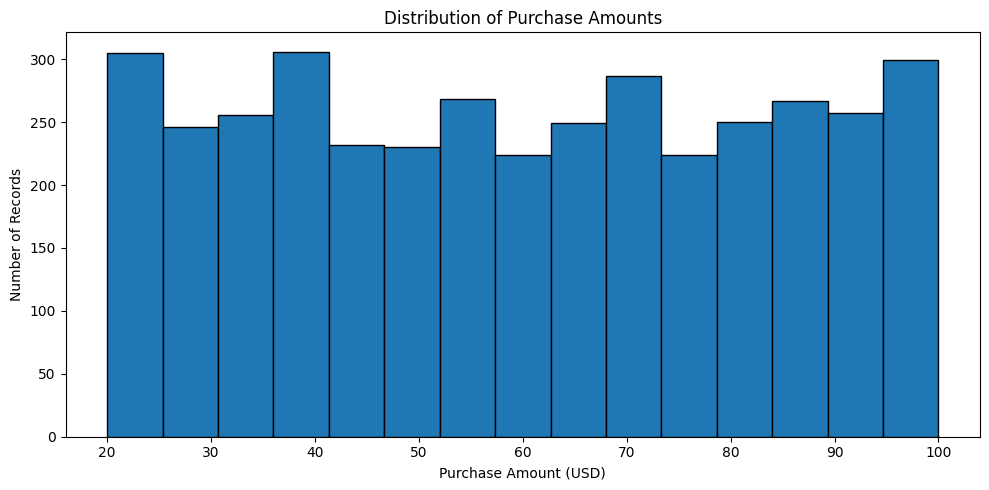

In [ ]:
plt.figure(figsize=(10, 5))

plt.hist(
    df_clean["purchase_amount"],
    bins=15,
    edgecolor="black"
)

plt.title("Distribution of Purchase Amounts")
plt.xlabel("Purchase Amount (USD)")
plt.ylabel("Number of Records")

plt.tight_layout()
plt.show()

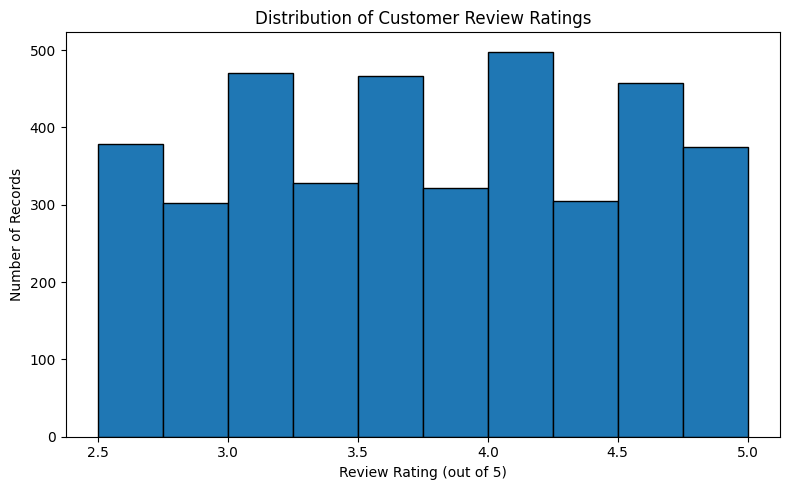

In [ ]:
plt.figure(figsize=(8, 5))

plt.hist(
    df_clean["review_rating"],
    bins=10,
    edgecolor="black"
)

plt.title("Distribution of Customer Review Ratings")
plt.xlabel("Review Rating (out of 5)")
plt.ylabel("Number of Records")

plt.tight_layout()
plt.show()

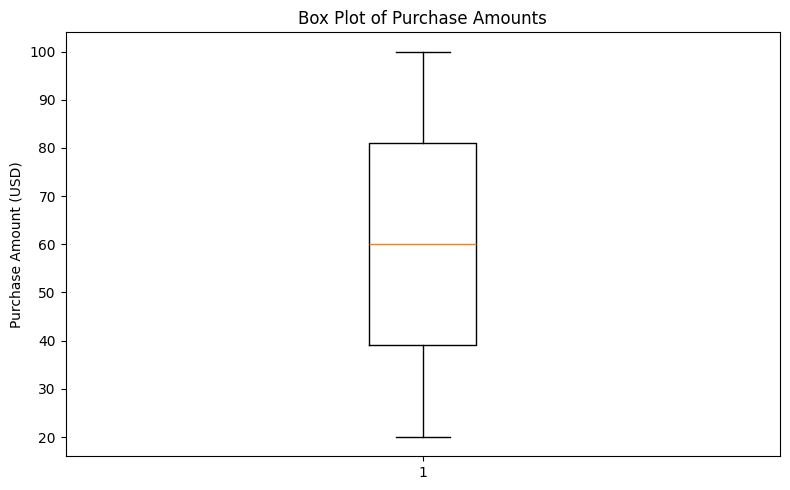

In [ ]:
plt.figure(figsize=(8, 5))

plt.boxplot(df_clean["purchase_amount"])

plt.title("Box Plot of Purchase Amounts")
plt.ylabel("Purchase Amount (USD)")

plt.tight_layout()
plt.show()

<Figure size 1000x500 with 0 Axes>

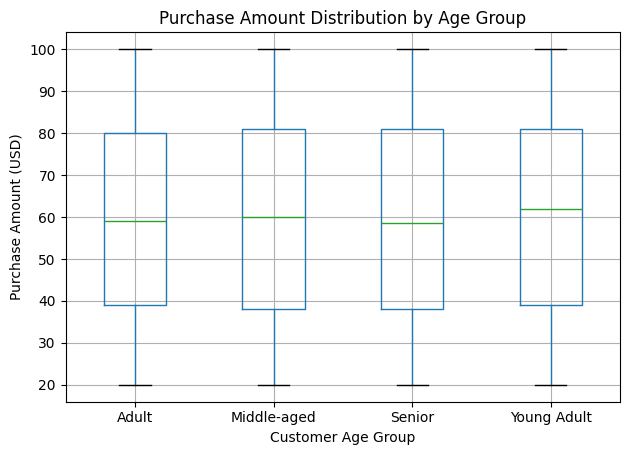

In [ ]:
plt.figure(figsize=(10, 5))

df_clean.boxplot(
    column="purchase_amount",
    by="age_group"
)

plt.title("Purchase Amount Distribution by Age Group")
plt.suptitle("")
plt.xlabel("Customer Age Group")
plt.ylabel("Purchase Amount (USD)")

plt.tight_layout()
plt.show()

<Figure size 800x500 with 0 Axes>

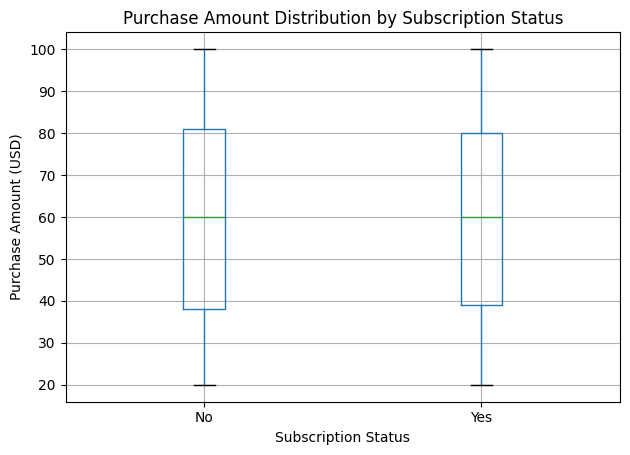

In [ ]:
plt.figure(figsize=(8, 5))

df_clean.boxplot(
    column="purchase_amount",
    by="subscription_status"
)

plt.title("Purchase Amount Distribution by Subscription Status")
plt.suptitle("")
plt.xlabel("Subscription Status")
plt.ylabel("Purchase Amount (USD)")

plt.tight_layout()
plt.show()

<Figure size 800x500 with 0 Axes>

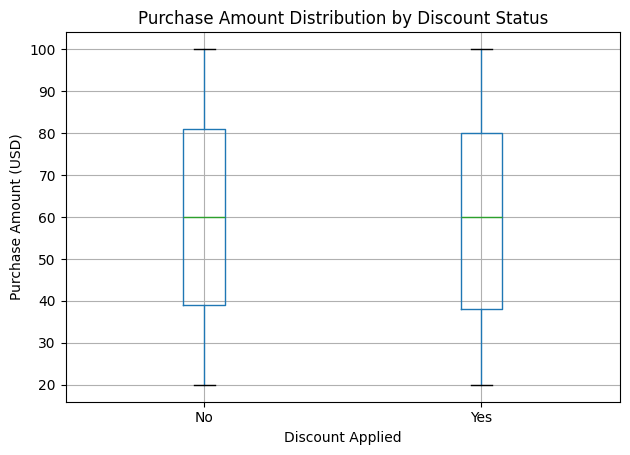

In [ ]:
plt.figure(figsize=(8, 5))

df_clean.boxplot(
    column="purchase_amount",
    by="discount_applied"
)

plt.title("Purchase Amount Distribution by Discount Status")
plt.suptitle("")
plt.xlabel("Discount Applied")
plt.ylabel("Purchase Amount (USD)")

plt.tight_layout()
plt.show()

<Figure size 900x500 with 0 Axes>

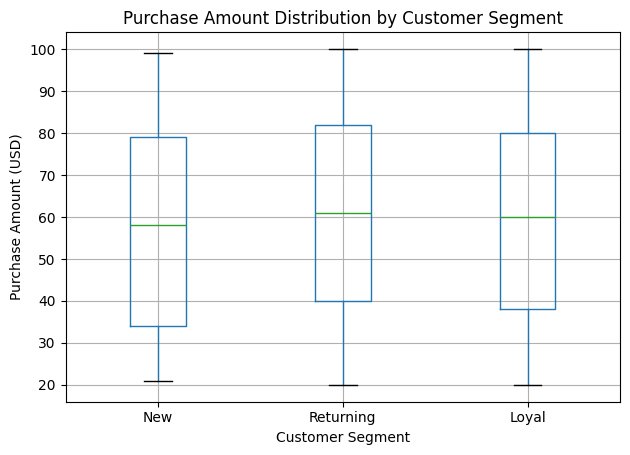

In [ ]:
plt.figure(figsize=(9, 5))

df_clean.boxplot(
    column="purchase_amount",
    by="customer_segment"
)

plt.title("Purchase Amount Distribution by Customer Segment")
plt.suptitle("")
plt.xlabel("Customer Segment")
plt.ylabel("Purchase Amount (USD)")

plt.tight_layout()
plt.show()

<Figure size 900x500 with 0 Axes>

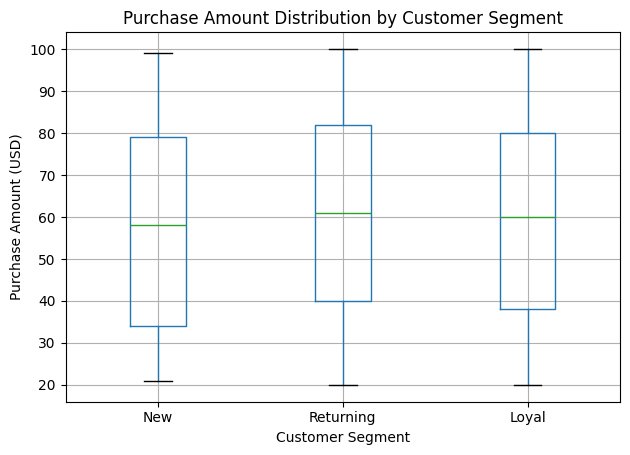

In [ ]:
plt.figure(figsize=(9, 5))

df_clean.boxplot(
    column="purchase_amount",
    by="customer_segment"
)

plt.title("Purchase Amount Distribution by Customer Segment")
plt.suptitle("")
plt.xlabel("Customer Segment")
plt.ylabel("Purchase Amount (USD)")

plt.tight_layout()
plt.show()

In [ ]:
df_clean.to_csv(
    "customer_shopping_behavior_cleaned.csv",
    index=False
)

print("Updated cleaned dataset saved successfully!")
print("Dataset shape:", df_clean.shape)

Updated cleaned dataset saved successfully!
Dataset shape: (3900, 21)


In [ ]:
from google.colab import files

files.download("customer_shopping_behavior_cleaned.csv")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
eda_summary = {
    "Total Records": len(df_clean),
    "Total Columns": len(df_clean.columns),
    "Unique Customers": df_clean["customer_id"].nunique(),
    "Total Recorded Purchase Amount": df_clean["purchase_amount"].sum(),
    "Average Purchase Amount": df_clean["purchase_amount"].mean(),
    "Average Customer Age": df_clean["age"].mean(),
    "Average Review Rating": df_clean["review_rating"].mean(),
    "Subscribed Customers": (
        df_clean["subscription_status"] == "Yes"
    ).sum(),
    "Customers Without Subscription": (
        df_clean["subscription_status"] == "No"
    ).sum(),
    "Missing Values": df_clean.isnull().sum().sum(),
    "Duplicate Rows": df_clean.duplicated().sum()
}

eda_summary_df = pd.DataFrame(
    list(eda_summary.items()),
    columns=["Metric", "Value"]
)

display(eda_summary_df.round(2))

,Metric,Value
0,Total Records,3900.00
1,Total Columns,21.00
2,Unique Customers,3900.00
3,Total Recorded Purchase Amount,233081.00
4,Average Purchase Amount,59.76
5,Average Customer Age,44.07
6,Average Review Rating,3.75
7,Subscribed Customers,1053.00
8,Customers Without Subscription,2847.00
9,Missing Values,0.00


In [ ]:
eda_summary_df.to_csv("customer_shopping_eda_summary.csv", index=False)

print("EDA summary saved successfully!")

EDA summary saved successfully!


In [ ]:
from google.colab import files

files.download("customer_shopping_eda_summary.csv")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
print("Dataset columns:")
for column in df_clean.columns:
    print(column)

Dataset columns:
customer_id
age
gender
item_purchased
category
purchase_amount
location
size
color
season
review_rating
subscription_status
shipping_type
discount_applied
promo_code_used
previous_purchases
payment_method
frequency_of_purchases
age_group
purchase_frequency_days
customer_segment


In [ ]:
!pip install -q sqlalchemy psycopg2-binary

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 4.3/4.3 MB 39.3 MB/s eta 0:00:00
